# Recipe: ALCOVE and the six category structures

*Partition a slow learning model with four parameters: define patterns that allow ties, plan and save a long run, read a partition you cannot plot directly, and check that the conclusions hold up.*

The [tutorial](tutorial.ipynb) partitioned a model with two parameters that runs in microseconds. Real models are rarely that kind. This recipe works through the analysis that introduced parameter space partitioning (Pitt, Kim, Navarro & Myung, 2006): ALCOVE, a model of how people learn categories, on six classic category-learning problems. It is the PyTorch counterpart of the [ALCOVE recipe of the R package](https://lenarddome.com/psp/articles/recipe-alcove.html) and shows how to:

- wrap a model for `PSP()`, and batch it so that many parameter sets run at once;
- define ordinal patterns that allow ties, and why that choice decides whether the analysis is feasible;
- plan a run when every evaluation simulates a whole experiment, and save it so you only run it once;
- read a partition of four parameters, which you cannot simply plot;
- check that the conclusions survive reasonable changes to the analysis.

In [1]:
import inspect
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from matplotlib import patches as mpatches
from matplotlib.lines import Line2D

from psp import PSP
from psp.models import alcove
from psp.models.alcove import (ALCOVE_PARAMETERS, TYPES, alcove_curves, alcove_training, describe_order,
                               human_curves, nosof94, to_alcove, type_ranks, weak_order)
from figure_style import figures, titled

show = figures("recipe-alcove")

blue, grey = "#2a78d6", "#adb5bd"

type_colours = dict(zip(TYPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]))
error_cols = [f"error_{t}" for t in TYPES]

# the saved results of the long run live next to this notebook, written by alcove/run_alcove.py
alcove_dir = Path("alcove")


def read_result(name):
    return pd.read_csv(alcove_dir / name)


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


## The six category structures

Shepard, Hovland and Jenkins (1961) built eight objects from three features with two values each, such as colour, size and shape. They split the eight objects into two categories of four, and asked people to learn which object belongs where. Up to relabelling the features, there are only six ways to make such a split, called Types I to VI. Each cube below is one type: its corners are the eight objects, coloured by category.

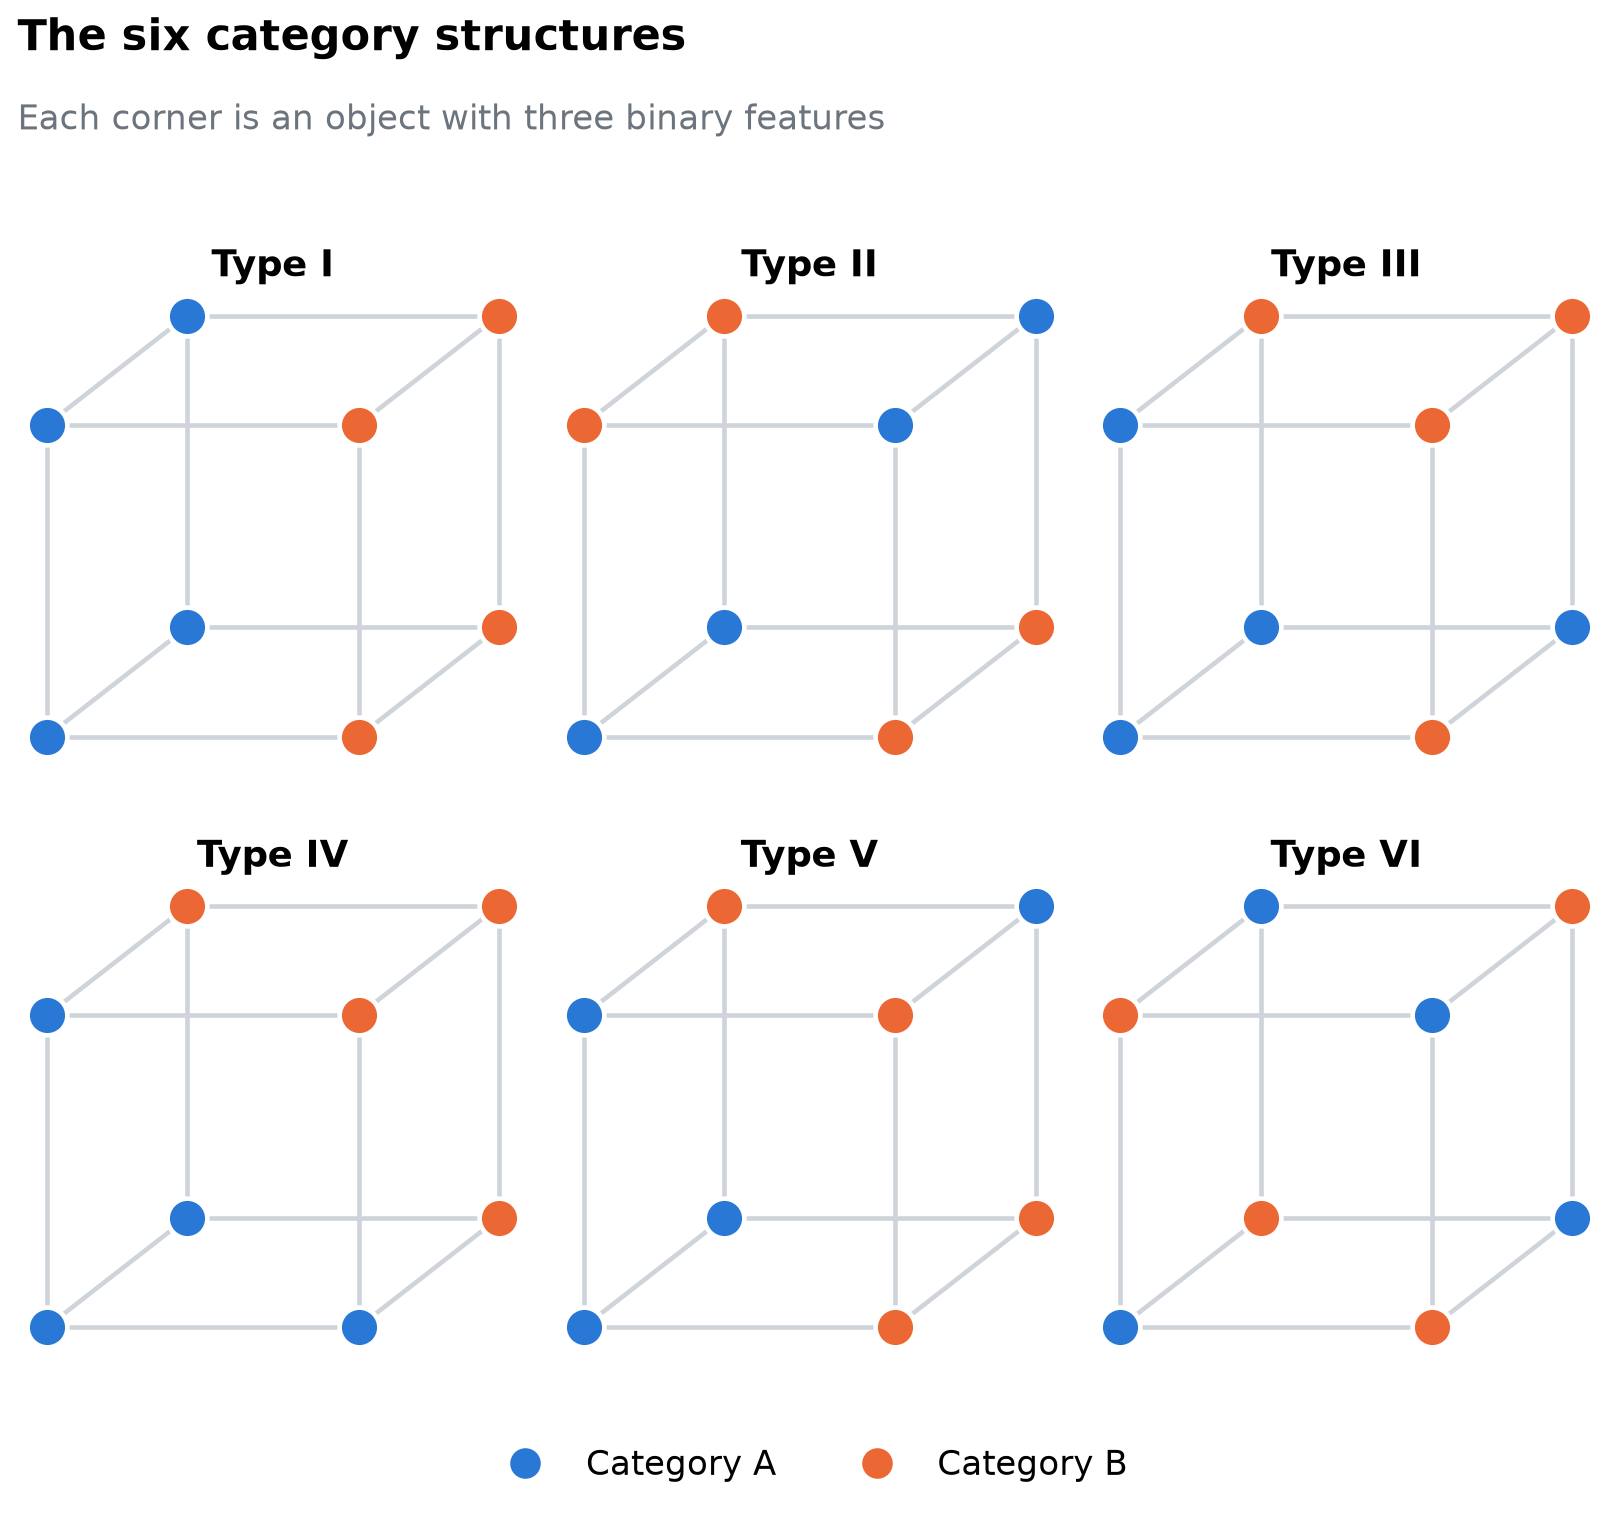

In [2]:
corners = [(x1, x2, x3) for x1 in (0, 1) for x2 in (0, 1) for x3 in (0, 1)]
category_a = {"I": ["000", "001", "010", "011"], "II": ["000", "001", "110", "111"],
              "III": ["000", "001", "010", "101"], "IV": ["000", "001", "010", "100"],
              "V": ["000", "001", "010", "111"], "VI": ["000", "011", "101", "110"]}
project = lambda x1, x2, x3: (x1 + 0.45 * x3, x2 + 0.35 * x3)   # oblique view
edges = [(a, b) for a in corners for b in corners if a < b and sum(abs(i - j) for i, j in zip(a, b)) == 1]
fig, axes = plt.subplots(2, 3, figsize=(7.5, 6.8))
for ax, (name, members) in zip(axes.ravel(), category_a.items()):
    for a, b in edges:
        ax.plot(*zip(project(*a), project(*b)), color="#ced4da", linewidth=1.5, zorder=1)
    for c in corners:
        colour = "#2a78d6" if "".join(map(str, c)) in members else "#eb6834"
        ax.plot(*project(*c), "o", markersize=13, color=colour, markeredgecolor="white", markeredgewidth=1.5, zorder=2)
    ax.set_title(f"Type {name}", loc="center", fontsize=12)
    ax.set_aspect("equal"); ax.axis("off")
handles = [Line2D([], [], marker="o", linestyle="", markersize=9, color=c, label=f"Category {k}")
           for k, c in (("A", "#2a78d6"), ("B", "#eb6834"))]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("The six category structures", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.905, "Each corner is an object with three binary features", color="#6c757d", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 0.9), h_pad=5)
show(fig, "category-structures")

Type I depends on one feature only. Type II needs two features in combination. Type VI needs all three, with no simpler rule. People learn the types in a reliable order. Here are the error rates of people in Nosofsky, Gluck, Palmeri, McKinley and Glauthier's (1994) replication, which ships with the catlearn package (Wills et al., 2025) and with `psp.models.alcove`:

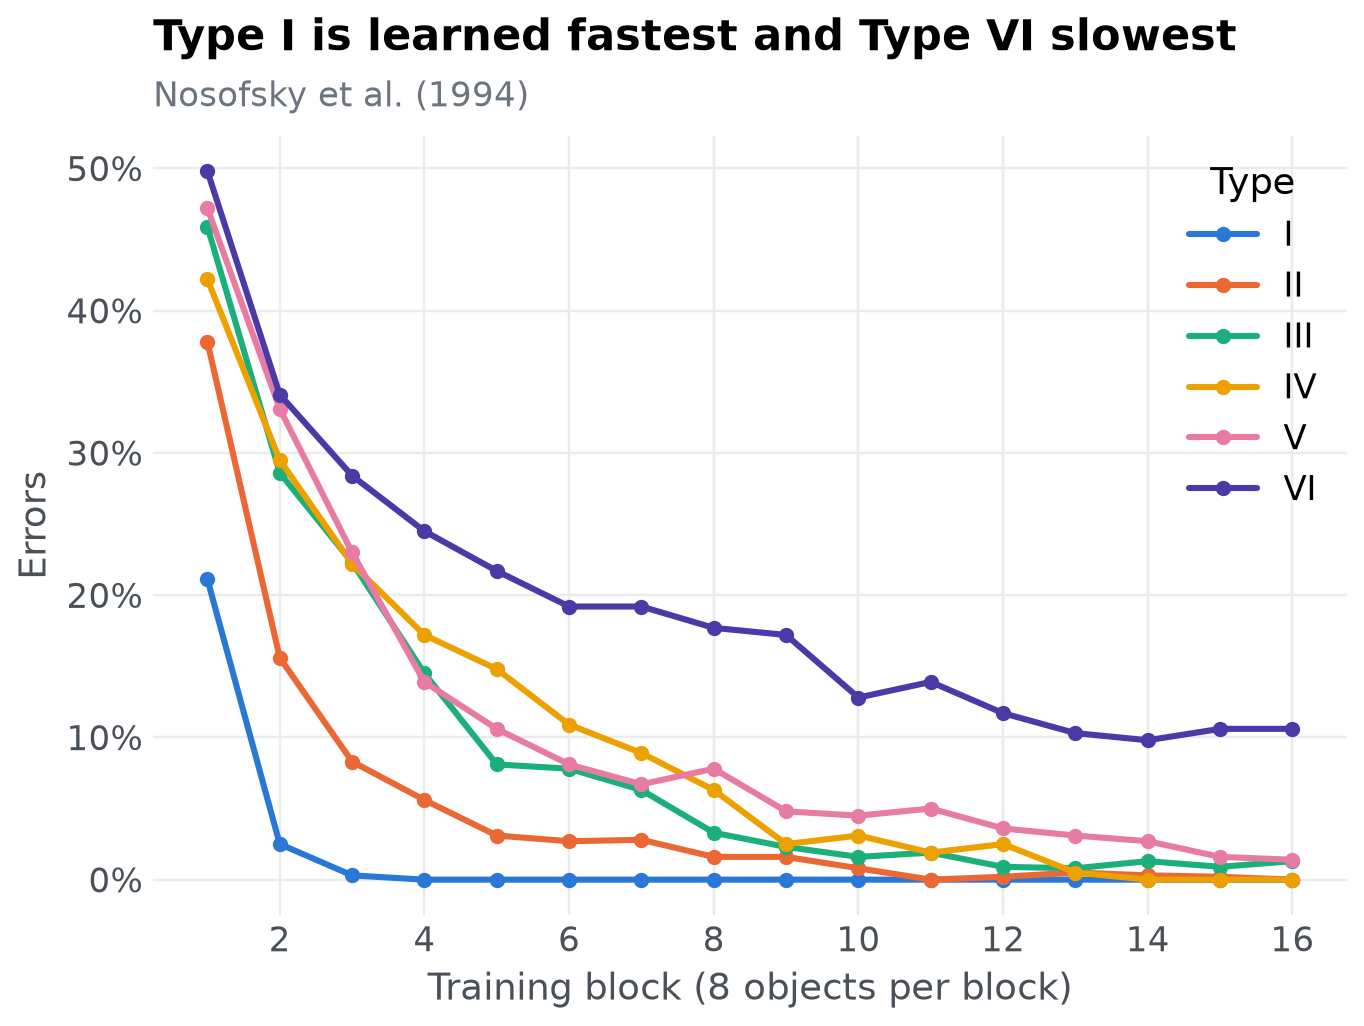

In [3]:
nosof = pd.DataFrame(nosof94(), columns=["type", "block", "error"])
nosof["type"] = [TYPES[int(t) - 1] for t in nosof.type]
fig, ax = plt.subplots()
for t in TYPES:
    d = nosof[nosof.type == t]
    ax.plot(d.block, d.error, "-o", color=type_colours[t], linewidth=2, markersize=4, label=t)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Training block (8 objects per block)")
ax.set_ylabel("Errors")
ax.legend(title="Type")
titled(ax, "Type I is learned fastest and Type VI slowest", "Nosofsky et al. (1994)")
show(fig, "nosofsky-learning-curves")

The qualitative finding is the ordering I < II < (III, IV, V) < VI: Types III, IV and V are about equally hard. Pitt et al. call this a *weak order*, an ordering that allows ties. The question for PSP: how many orderings of the six types can ALCOVE produce, and is this one of them?

## The model

ALCOVE (Kruschke, 1992) learns categories by storing each object it sees as an exemplar and learning which category each exemplar points to. When an object with features $x_i$ appears, each stored exemplar $j$, with features $h_{ji}$, responds according to how similar the object is to it:

$$
a_j = \exp\Big(-c \sum_i \alpha_i \, |h_{ji} - x_i|\Big).
$$

The *specificity* $c$ sets how quickly similarity falls with distance, and the *attention weights* $\alpha_i$ set how much each feature counts. Each category $k$ collects evidence from the exemplars through association weights $w_{kj}$,

$$
o_k = \sum_j w_{kj} \, a_j,
$$

and the model chooses category $K$ with probability

$$
P(K) = \frac{\exp(\phi \, o_K)}{\sum_k \exp(\phi \, o_k)},
$$

where $\phi$ sets how consistently it picks the category with more evidence. After feedback, ALCOVE learns by gradient descent on the error between $o_k$ and a target $t_k$: the association weights change at rate $\lambda_w$ and the attention weights at rate $\lambda_a$,

$$
\Delta w_{kj} = \lambda_w (t_k - o_k)\, a_j, \qquad
\Delta \alpha_i = -\lambda_a \sum_j \Big[\sum_k (t_k - o_k)\, w_{kj}\Big] a_j \, c \, |h_{ji} - x_i|.
$$

The targets are "humble": the model is only corrected when its evidence points the wrong way, or not far enough. Learning to attend to the features that matter is what lets ALCOVE learn Type II faster than Types III to V.

That leaves four free parameters. We use the ranges Pitt et al. (2006) used:

| Parameter | Meaning | Range |
|---|---|---|
| $c$ | specificity: how fast similarity falls with distance | 0 to 20 |
| $\phi$ | decision consistency | 0 to 6 |
| $\lambda_w$ | learning rate of the association weights | 0 to 0.2 |
| $\lambda_a$ | learning rate of attention | 0 to 0.2 |

Pitt et al. call the learning rates $\eta_w$ and $\eta_a$. In catlearn, and here, they are `lw` and `la`.

## Step 1: wrap the model

catlearn implements ALCOVE as `slpALCOVE()`, which runs the model through a sequence of training trials, one parameter set at a time. `psp.models.alcove` ports it to PyTorch as `alcove()`, which runs a whole *batch* of parameter sets through a whole batch of training sequences at once. It reproduces catlearn's trial-by-trial probabilities to machine precision (the package tests check this against catlearn's output), and it is what makes this recipe's long run affordable: every iteration of PSP evaluates all its proposals in one call.

The training sequence is part of the experiment, not of the model, so we build it once, outside the function `PSP()` calls. catlearn's `nosof94train()` shuffles each block of eight objects with a fixed seed, so the model gives the same answer every time it is called with the same parameters. The orders catlearn generates are shipped with the package, so the analysis here sees exactly the trials the R analysis saw. Each simulated learner gets its own order, and averaging over a few of them smooths out the effect of any one order:

In [4]:
print(inspect.getsource(alcove_training))

def alcove_training(learners: int = 5, seed: int = 7624) -> torch.Tensor:
    """One training sequence per type and simulated learner, in catlearn's trial order.

    The orders catlearn's ``nosof94train()`` generates with R's random number
    generator are shipped for ``seed`` 7624 with 5 and 20 learners, and for seeds
    11, 22, 33 and 44 with 5 learners (the settings of the ALCOVE recipe). Other
    settings fall back to :func:`nosof94train` and NumPy's generator.

    Returns
    -------
    torch.Tensor
        Shape ``(6 * learners * 16 * 8 * 2, 12)``, ``float64``: types I to VI in
        turn, each with ``learners`` sequences of 16 blocks.
    """
    name = f"nosof94train_seed{seed}_learners{learners}.csv.gz"
    resource = resources.files("psp.data").joinpath(name)
    if resource.is_file():
        with resource.open("rb") as raw, gzip.open(raw, "rt", encoding="utf-8") as text:
            reader = csv.reader(text)
            header = next(reader)
            assert tuple

`PSP()` uses one `radius` for every parameter (it also accepts one per parameter, but we follow the R recipe), while $c$ ranges over 0 to 20 and the learning rates over 0 to 0.2. A step that suits one would be far too large or too small for the other. The fix is to let `PSP()` search the unit hypercube, $[0, 1]^4$, and stretch each coordinate onto its parameter's range inside the model:

In [5]:
ALCOVE_PARAMETERS

AlcoveParameters(name=('c', 'phi', 'lw', 'la'), lower=(0.01, 0.01, 0.001, 0.001), upper=(20.0, 6.0, 0.2, 0.2))

In [6]:
print(inspect.getsource(to_alcove))

def to_alcove(
    unit: torch.Tensor, parameters: AlcoveParameters = ALCOVE_PARAMETERS
) -> dict[str, torch.Tensor]:
    """Stretch points of the unit hypercube onto ALCOVE's parameter ranges.

    ``unit`` has shape ``(n, 4)``; the result maps ``c``, ``phi``, ``lw`` and
    ``la`` to tensors of shape ``(n,)``. ``parameters`` gives the ranges: those of
    Pitt et al. by default, or :data:`ALCOVE_PARAMETERS_FULL`.
    """
    unit = unit.reshape(-1, 4)
    lower = torch.tensor(parameters.lower, dtype=unit.dtype, device=unit.device)
    upper = torch.tensor(parameters.upper, dtype=unit.dtype, device=unit.device)
    values = lower + unit * (upper - lower)
    return {name: values[:, i] for i, name in enumerate(parameters.name)}



The lower bounds are just above 0. Proposals beyond the bounds are moved onto them, so the model really is evaluated at the bounds, and ALCOVE rejects a learning rate of exactly 0. Make sure your model works at the edges of the space, not just inside it.

The model function runs ALCOVE and returns the error rate of each type in each of the 16 blocks:

In [7]:
print(inspect.getsource(alcove_curves))

def alcove_curves(
    unit: torch.Tensor,
    training: torch.Tensor,
    *,
    chunk: int = 256,
    parameters: AlcoveParameters = ALCOVE_PARAMETERS,
) -> torch.Tensor:
    """Error rate of each type in each block for parameter sets on the unit hypercube.

    This is the ``model`` of the ALCOVE recipe. ``unit`` has shape ``(n, 4)`` and
    is mapped onto ALCOVE's ranges, ``parameters``, with :func:`to_alcove`.
    ``training`` is a matrix from :func:`alcove_training`. The result has shape
    ``(n, 96)``: the 16 blocks of Type I, then of Type II, and so on, each averaged
    over the simulated learners.

    ``chunk`` bounds how many parameter sets run at once, to limit memory.
    """
    unit = unit.reshape(-1, 4)
    seq = sequences(training.to(unit.device, unit.dtype))
    cond = seq[:, 0, 1].long() - 1  # type of each sequence, 0-5
    block = seq[:, :, 2].long() - 1  # block of each trial, 0-15
    correct_is_first = seq[:, :, 7] == 1  # t1 == 1: category A is correct
    n_

That is 96 numbers per evaluation, so `responses = 96`. Returning the whole learning curves costs nothing extra, and with `save=True` they are all kept for later.

In [8]:
training = alcove_training(learners=5, seed=7624)


def model(par):
    return alcove_curves(par, training)

## Step 2: decide what counts as a different pattern

This decision matters more than any other. Pitt et al. define a pattern as the weak order of the six types by how hard they are, and with six types there are 4,683 possible weak orders: one with all types tied, 62 with two groups, up to 720 strict rankings.

Ties need a rule. Mean error rates are never exactly equal, so we have to say when two types count as equally hard. A first attempt compares every pair of types and calls them tied when their error rates are within 0.025. That fails badly: the ties need not be consistent (III can tie with IV, and IV with V, while III differs from V), so the patterns are not weak orders at all. In a pilot run, that definition produced 298 patterns within 20 iterations, still growing fast, and every iteration had to evaluate all of them.

Pitt et al. instead grouped the types with a clustering method (Kontkanen et al., 2005), which always yields a proper weak order. We use a simpler rule with the same guarantee: sort the six error rates, and start a new group wherever the gap to the next type is larger than 0.025.

In [9]:
print(inspect.getsource(weak_order))

def weak_order(curves: torch.Tensor, gap: float = 0.025) -> torch.Tensor:
    """The weak order of the six types by mean error, as a 6 x 6 comparison matrix.

    This is the ``discretize`` of the ALCOVE recipe. The six mean errors are sorted
    and a new group starts wherever the gap to the next type exceeds ``gap``. The
    entry ``(i, j)`` is 1 when type ``i`` is harder than type ``j``, -1 when easier
    and 0 when they are tied. ``curves`` may be ``(96,)``, ``(n, 96)`` or ``(n, 6)``
    (mean errors); the result has shape ``(n, 6, 6)``, or ``(6, 6)`` for a vector.
    """
    single = curves.ndim == 1
    curves = curves.reshape(1, -1) if single else curves
    n_types = len(TYPES)
    if curves.shape[1] == n_types:
        error = curves
    else:
        error = curves.reshape(curves.shape[0], n_types, -1).mean(dim=2)
    sorted_error, order = error.sort(dim=1)
    new_group = torch.ones_like(sorted_error, dtype=torch.int64)
    new_group[:, 1:] = (sorted_error.diff(dim=1) > ga

In [10]:
print(inspect.getsource(describe_order))

def describe_order(pattern: torch.Tensor) -> str:
    """Write a weak order the usual way, easiest first: ``"I < II < (III, IV, V) < VI"``."""
    rank = (torch.as_tensor(pattern) > 0).sum(dim=1).tolist()  # how many types each is harder than
    groups: dict[int, list[str]] = {}
    for name, r in zip(TYPES, rank, strict=True):
        groups.setdefault(int(r), []).append(name)
    parts = []
    for r in sorted(groups):
        names = groups[r]
        parts.append(f"({', '.join(names)})" if len(names) > 1 else names[0])
    return " < ".join(parts)



Applied to the human data, it recovers the classic ordering:

In [11]:
human = describe_order(weak_order(human_curves()))
human

'I < II < (III, IV, V) < VI'

`weak_order()` returns a 6 × 6 matrix per parameter set, which is what `PSP()` needs from `discretize`, and `describe_order()` writes one in the usual notation:

In [12]:
def discretize(curves):
    return weak_order(curves, gap=0.025)

The threshold 0.025 is a choice, so the robustness check at the end repeats the analysis with other values.

## Step 3: plan the run

Before a long run, time one evaluation, and a batch of them. With a batched model the second number matters more: PSP evaluates every pattern that is still filling in one call, so the cost of an iteration is the cost of one batch, not of one evaluation times the number of patterns.

In [13]:
import time

for n in (1, 50):
    start = time.perf_counter()
    model(torch.full((n, 4), 0.5, dtype=torch.float64))
    print(f"{n:>3} parameter set{'s' if n > 1 else ''}: {time.perf_counter() - start:.2f} s")

  1 parameter set: 0.05 s
 50 parameter sets: 0.11 s


In [14]:
info = read_result("run-info.csv").set_index("stage")
psp_info = info.loc["psp"]
display(Markdown(f"""
Each evaluation simulates {6 * 5} learners working through 16 blocks. The cost of a run is roughly the number of iterations times the cost of one batch, and the batch holds every pattern that is still below `population`. Patterns are unknown before you search, so a short pilot run is the best estimate. The full run used `population = 50` and 20 random starting points:
"""))


Each evaluation simulates 30 learners working through 16 blocks. The cost of a run is roughly the number of iterations times the cost of one batch, and the batch holds every pattern that is still below `population`. Patterns are unknown before you search, so a short pilot run is the best estimate. The full run used `population = 50` and 20 random starting points:


```python
torch.manual_seed(2026)
control = {
    "lower": [0] * 4, "upper": [1] * 4,
    "init": torch.rand(20, 4, dtype=torch.float64),
    "radius": 0.15,
    "population": 50,
    "iterations": 2000,
    "parameter_names": list(ALCOVE_PARAMETERS.name),
    "stimuli_names": [f"{t}_{b}" for t in TYPES for b in range(1, 17)],
    "dimensionality": 6,
    "responses": 96,
}
result = PSP(model, discretize, control, save=True, path="alcove", quiet=True)
```

In [15]:
display(Markdown(f"""
It took {psp_info.seconds / 60:.0f} minutes for {psp_info.evaluations:,.0f} evaluations on this machine's CPU; the R package's run took about 9 minutes on an Apple M2 Pro, calling the model once per parameter set. {"It ran to the cap of 2,000 iterations: a few rare patterns never reached a population of 50, a reminder that tiny regions fill slowly." if psp_info.iterations >= 2000 else f"It stopped on its own after {psp_info.iterations:,.0f} iterations."} Run something that long once, outside the document that reports it, and save what you need. The script that ran this analysis is [`alcove/run_alcove.py`](alcove/run_alcove.py); it keeps each evaluation's parameters, the mean error of each type and its weak order, and this recipe reads that file.
"""))


It took 3 minutes for 14,369 evaluations on this machine's CPU; the R package's run took about 9 minutes on an Apple M2 Pro, calling the model once per parameter set. It ran to the cap of 2,000 iterations: a few rare patterns never reached a population of 50, a reminder that tiny regions fill slowly. Run something that long once, outside the document that reports it, and save what you need. The script that ran this analysis is [`alcove/run_alcove.py`](alcove/run_alcove.py); it keeps each evaluation's parameters, the mean error of each type and its weak order, and this recipe reads that file.


## Step 4: read the results

In [16]:
run = read_result("psp-run.csv.gz")
uniform = read_result("uniform.csv.gz")
found = run.order.unique()
print(len(found))
print(human in found)

44
True


In [17]:
display(Markdown(f"ALCOVE produced {len(found)} of the 4,683 possible weak orders, about {pct(len(found) / 4683, 1)}, and the human ordering is one of them. Pitt et al. found between 32 and 122 patterns per run with their clustering rule, so the picture is similar: ALCOVE is far from able to produce any ordering at all."))

ALCOVE produced 44 of the 4,683 possible weak orders, about 0.9%, and the human ordering is one of them. Pitt et al. found between 32 and 122 patterns per run with their clustering rule, so the picture is similar: ALCOVE is far from able to produce any ordering at all.

### How much of the space produces each pattern?

The parameter sets PSP records are not an even sample of the space: every pattern is sampled until it is full, however small its region. To compare region sizes, `run_alcove.py` also evaluated ALCOVE at 4,000 parameter sets spread evenly over the space, in a single batched call:

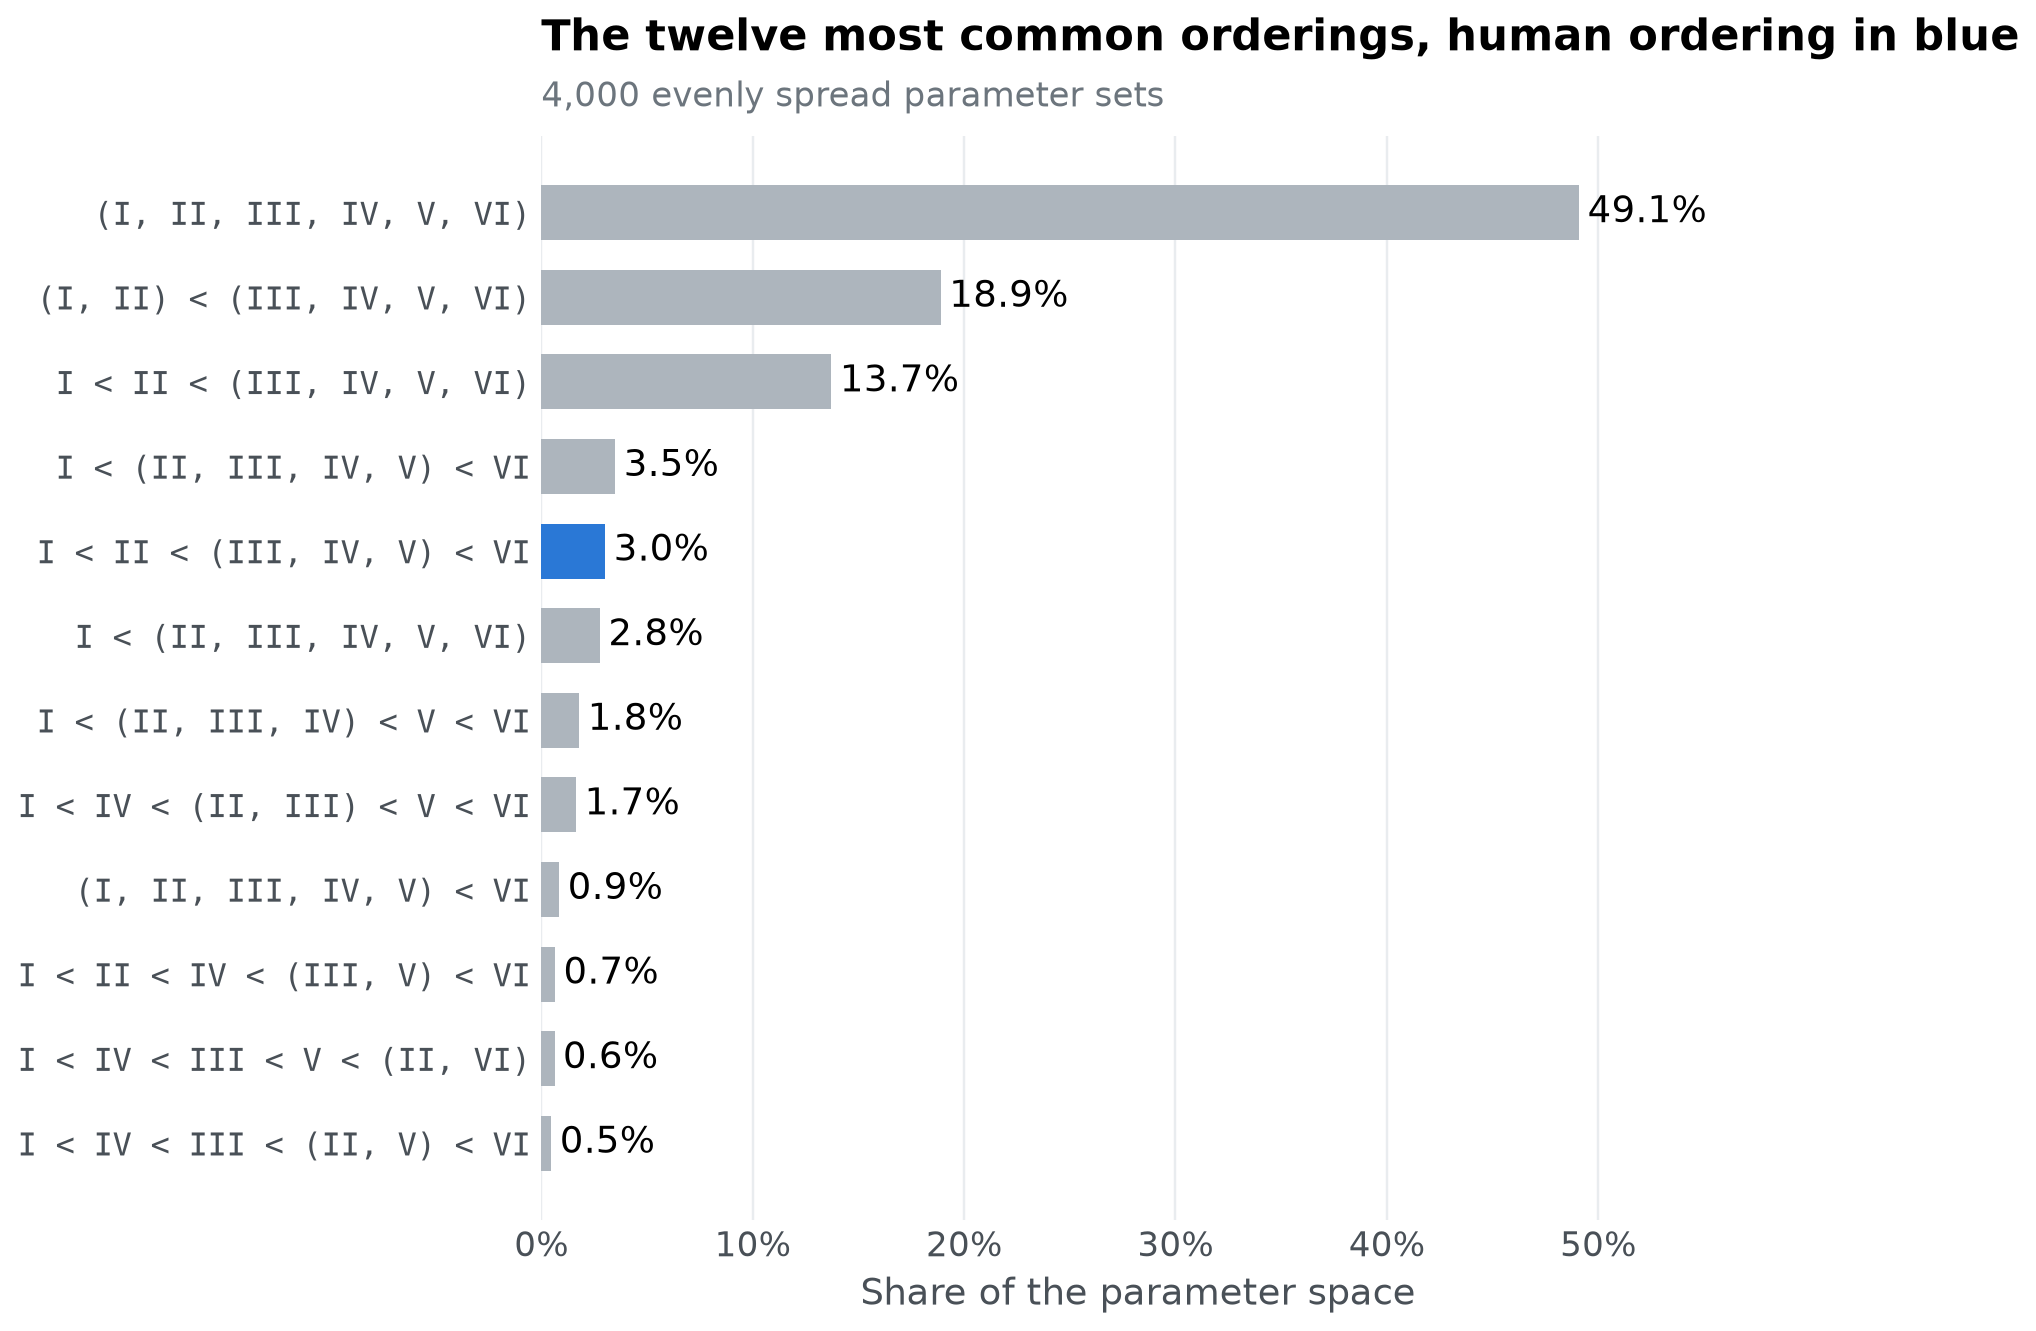

In [18]:
share = uniform.order.value_counts(normalize=True)
top = share.iloc[:12][::-1]
fig, ax = plt.subplots(figsize=(7, 6.4))
ax.barh(top.index, top.values, color=[blue if o == human else grey for o in top.index], height=0.65)
for y, value in enumerate(top.values):
    ax.text(value + 0.004, y, pct(value, 1), va="center")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, top.max() * 1.15)
ax.set_xlabel("Share of the parameter space")
ax.tick_params(axis="y", labelsize=10.5)
for tick in ax.get_yticklabels():
    tick.set_family("monospace")
ax.grid(axis="y", visible=False)
titled(ax, "The twelve most common orderings, human ordering in blue", f"{len(uniform):,} evenly spread parameter sets")
show(fig, "common-orderings")

In [19]:
tied = uniform.order == "(I, II, III, IV, V, VI)"
tied_error = uniform.loc[tied, error_cols].mean(axis=1)
display(Markdown(f"""
The most common outcome, `{share.index[0]}`, covers {pct(share.iloc[0])} of the space: parameter values where ALCOVE finds all six types equally hard. Mostly that is because it learns them all quickly. {pct((tied_error < 0.05).mean())} of these parameter sets average under 5% errors, and only {pct((tied_error > 0.4).mean())} stay near chance. It happens most at high specificity $c$, where each stored exemplar responds almost only to itself. ALCOVE then memorises the eight objects one by one, and the structure of the categories stops mattering. The human ordering covers {pct((uniform.order == human).mean(), 1)} of the space and is the {list(share.index).index(human) + 1}. most common ordering. The rest of the {uniform.order.nunique()} orderings in the even sample share what remains, many of them in very small regions.
"""))


The most common outcome, `(I, II, III, IV, V, VI)`, covers 49% of the space: parameter values where ALCOVE finds all six types equally hard. Mostly that is because it learns them all quickly. 65% of these parameter sets average under 5% errors, and only 8% stay near chance. It happens most at high specificity $c$, where each stored exemplar responds almost only to itself. ALCOVE then memorises the eight objects one by one, and the structure of the categories stops mattering. The human ordering covers 3.0% of the space and is the 5. most common ordering. The rest of the 36 orderings in the even sample share what remains, many of them in very small regions.


### Why not estimate volumes the way Pitt et al. did?

Pitt et al. (2006, Appendix B) estimated each region's volume differently. They ran a Markov chain inside every region, whose target is uniform on that region, so that its samples spread evenly over it. They fit an ellipsoid to each chain from its mean and covariance matrix $\mathbf{S}$, and corrected the ellipsoid's volume by hit-or-miss Monte Carlo: draw $n$ points evenly inside the ellipsoid, run the model on each, and count the $k$ that produce the region's pattern. In $d$ dimensions, with $V_d$ the volume of a ball of radius 1,

$$
V_R = \frac{k}{n}\, V_d\,(d + 2)^{d/2}\,|\mathbf{S}|^{1/2}.
$$

The `volume` stage of `run_alcove.py` implements this: a Metropolis chain of 600 steps in each region, tuned to the 20% to 25% acceptance rate Pitt et al. recommend, followed by 200 hit-or-miss points. With a batched model the chains of all regions advance together, one model call per step. On ALCOVE it does not give usable volumes:

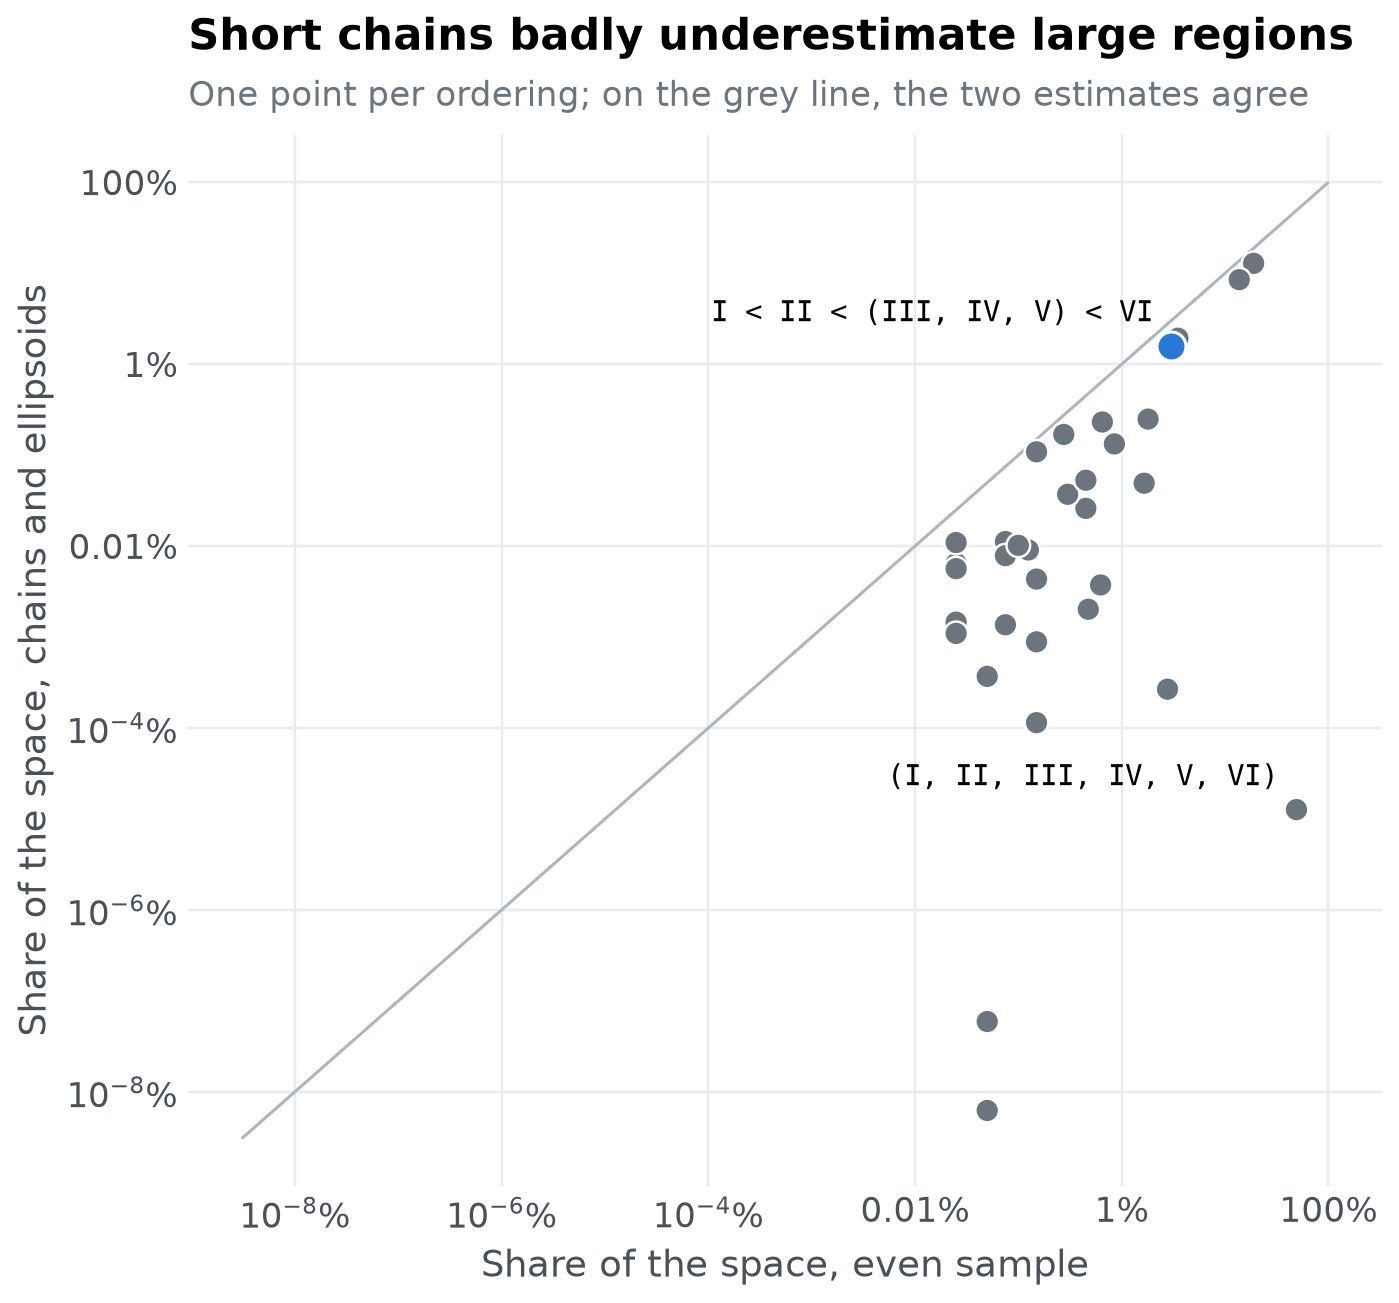

In [20]:
volumes = read_result("volumes.csv")
volumes["even"] = volumes.order.map(uniform.order.value_counts(normalize=True)).fillna(0)
compared = volumes[volumes.volume.notna() & (volumes.volume > 0) & (volumes.even > 0)]
fig, ax = plt.subplots(figsize=(7, 6.2))
lo, hi = min(compared.even.min(), compared.volume.min()) * 0.5, max(compared.even.max(), compared.volume.max()) * 2
ax.plot([lo, hi], [lo, hi], color=grey, linewidth=1)
ax.scatter(compared.even, compared.volume, s=60, c=[blue if o == human else "#6c757d" for o in compared.order],
           edgecolors="white", linewidths=0.8, zorder=3)
at_human = compared[compared.order == human]
ax.scatter(at_human.even, at_human.volume, s=90, color=blue, edgecolors="white", linewidths=1, zorder=4)
for _, r in compared[compared.order.isin([human, share.index[0]])].iterrows():
    ax.annotate(r.order, (r.even, r.volume), textcoords="offset points", xytext=(-6, 8), ha="right", family="monospace", fontsize=9.5)
ax.set_xscale("log"); ax.set_yscale("log")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(lambda v, _: f"{100 * v:g}%" if 100 * v >= 0.01 else f"$10^{{{round(np.log10(100 * v))}}}$%")
ax.set_xlabel("Share of the space, even sample")
ax.set_ylabel("Share of the space, chains and ellipsoids")
titled(ax, "Short chains badly underestimate large regions", "One point per ordering; on the grey line, the two estimates agree")
show(fig, "volume-estimates")

In [21]:
total_volume = volumes.volume.sum()
tied_ratio = (volumes.even[volumes.order == share.index[0]].iloc[0] / volumes.volume[volumes.order == share.index[0]].iloc[0])
display(Markdown(f"""
The regions' volumes should add up to the whole space, but these add up to {pct(total_volume)} of it. The largest region, `{share.index[0]}`, comes out about {tied_ratio:,.2g} times smaller than the even sample says. Two things go wrong. A chain of a few hundred steps, each small enough to be accepted a fifth of the time, only explores a patch of a large region, so its ellipsoid is far too small; Pitt et al. used 60,000 samples per region. And the method assumes every pattern occupies one connected region, while all-tied learning comes in two separate parts, fast learners and learners who hardly learn at all. An ellipsoid fitted around both would mostly cover other orderings.

The even sample has neither problem: it needs no assumption about the shape of a region, and its error shrinks with the number of points. Its weakness is that it cannot size a region too small to be hit at all, so for a model with very small regions that matter, long chains would be worth their cost.
"""))


The regions' volumes should add up to the whole space, but these add up to 26% of it. The largest region, `(I, II, III, IV, V, VI)`, comes out about 3.9e+06 times smaller than the even sample says. Two things go wrong. A chain of a few hundred steps, each small enough to be accepted a fifth of the time, only explores a patch of a large region, so its ellipsoid is far too small; Pitt et al. used 60,000 samples per region. And the method assumes every pattern occupies one connected region, while all-tied learning comes in two separate parts, fast learners and learners who hardly learn at all. An ellipsoid fitted around both would mostly cover other orderings.

The even sample has neither problem: it needs no assumption about the shape of a region, and its error shrinks with the number of points. Its weakness is that it cannot size a region too small to be hit at all, so for a model with very small regions that matter, long chains would be worth their cost.


### What the patterns look like

An ordering is easier to judge when you can see the error rates behind it. Each panel shows the mean error of each type for the parameter sets in one of the most common orderings, one line per parameter set:

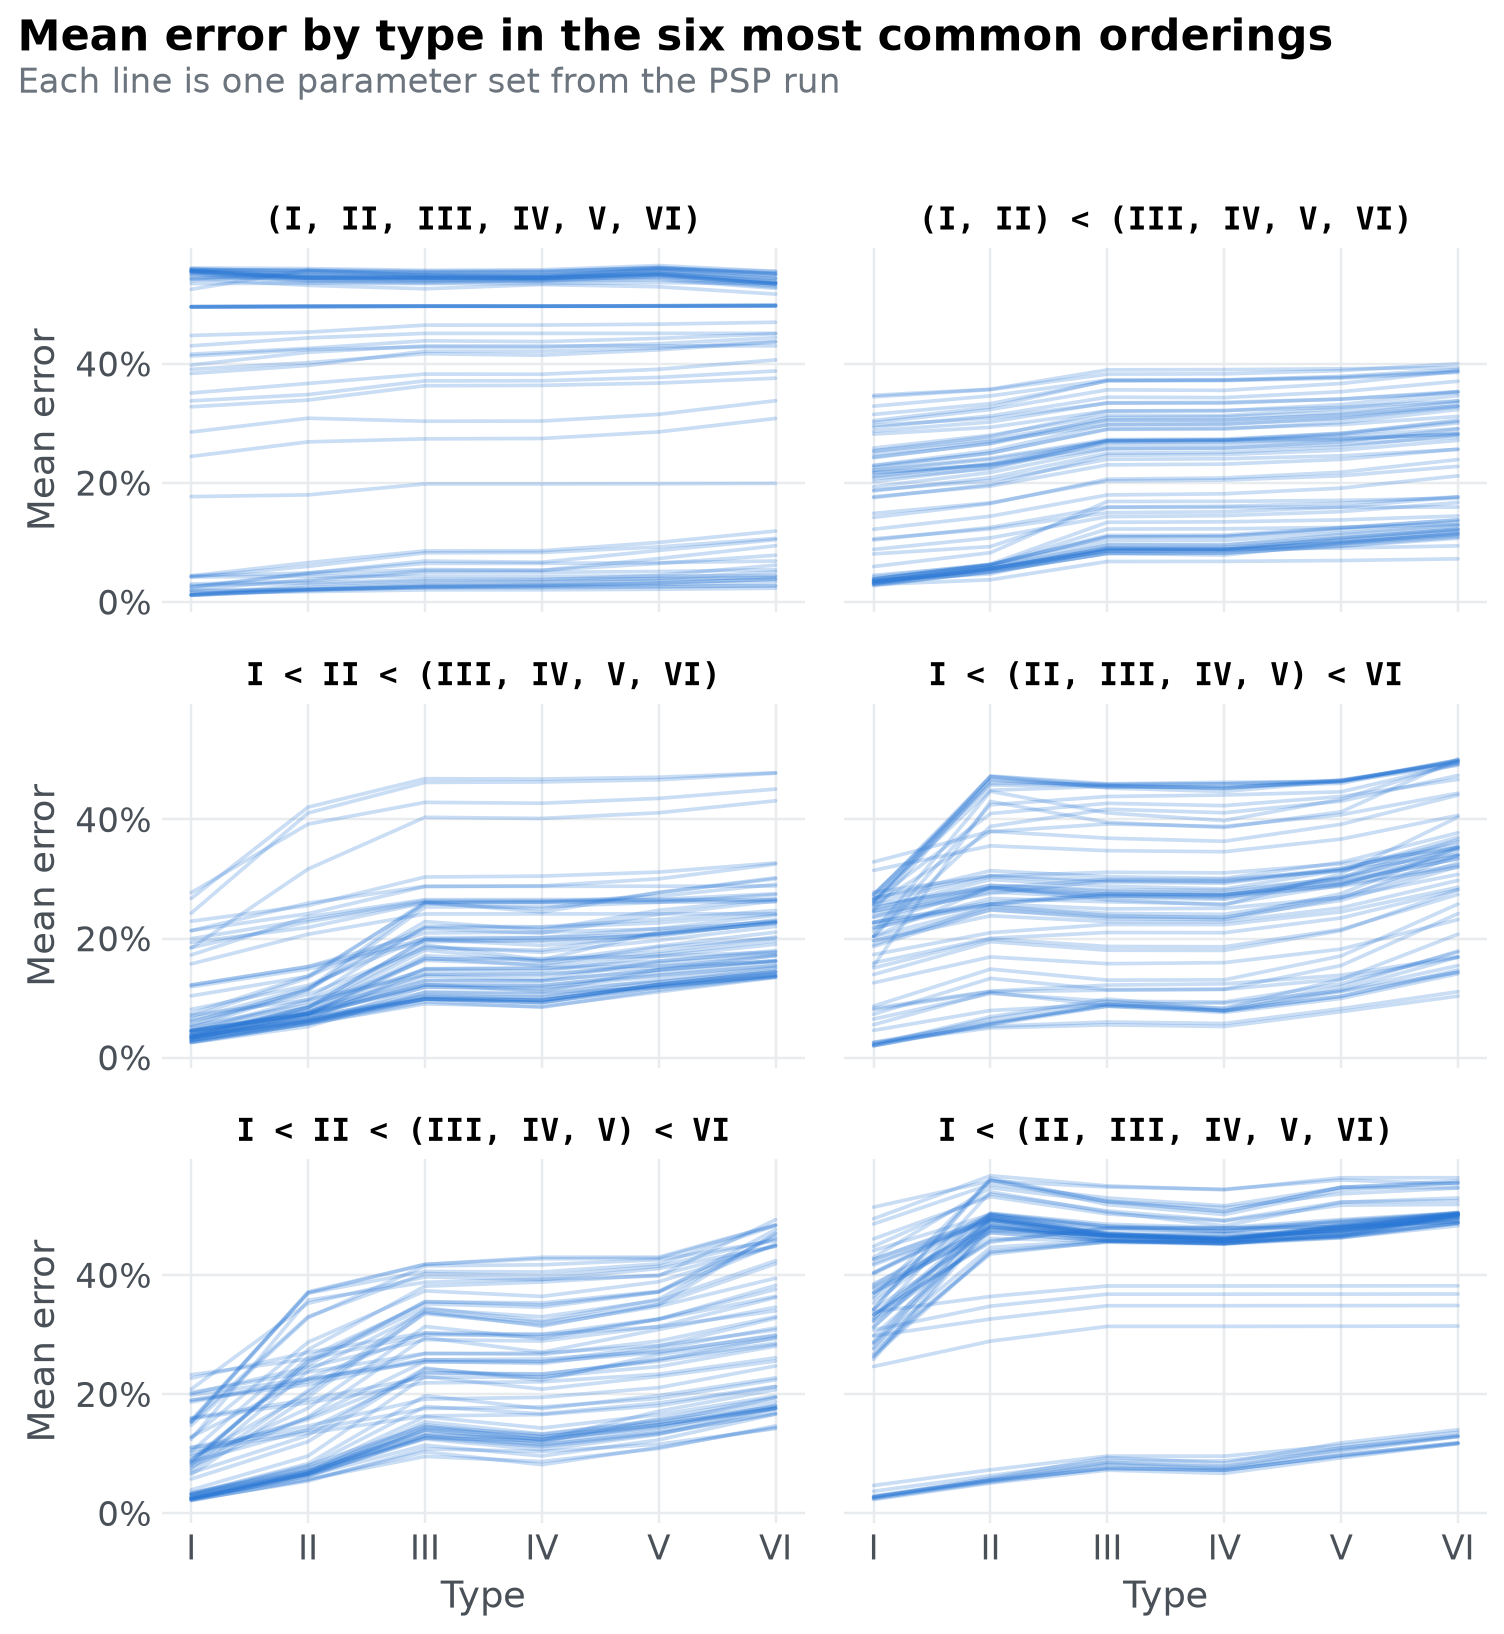

In [22]:
shown = list(share.index[:6])
fig, axes = plt.subplots(3, 2, figsize=(7, 7.6), sharex=True, sharey=True)
for ax, o in zip(axes.ravel(), shown):
    d = run.loc[run.order == o, error_cols].iloc[:60]
    for _, row in d.iterrows():
        ax.plot(TYPES, row.values, color=blue, alpha=0.25, linewidth=1.2)
    ax.set_title(o, loc="center", fontsize=10, family="monospace")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean error")
for ax in axes[-1]:
    ax.set_xlabel("Type")
fig.suptitle("Mean error by type in the six most common orderings", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.935, "Each line is one parameter set from the PSP run", color="#6c757d", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94))
show(fig, "error-by-type")

### Where the human ordering lives

With four parameters there is no single map to draw. One useful view is how often each parameter's values produce the human ordering. Split each parameter's range into ten bins and, within each bin, take the share of the even sample that gives the human ordering:

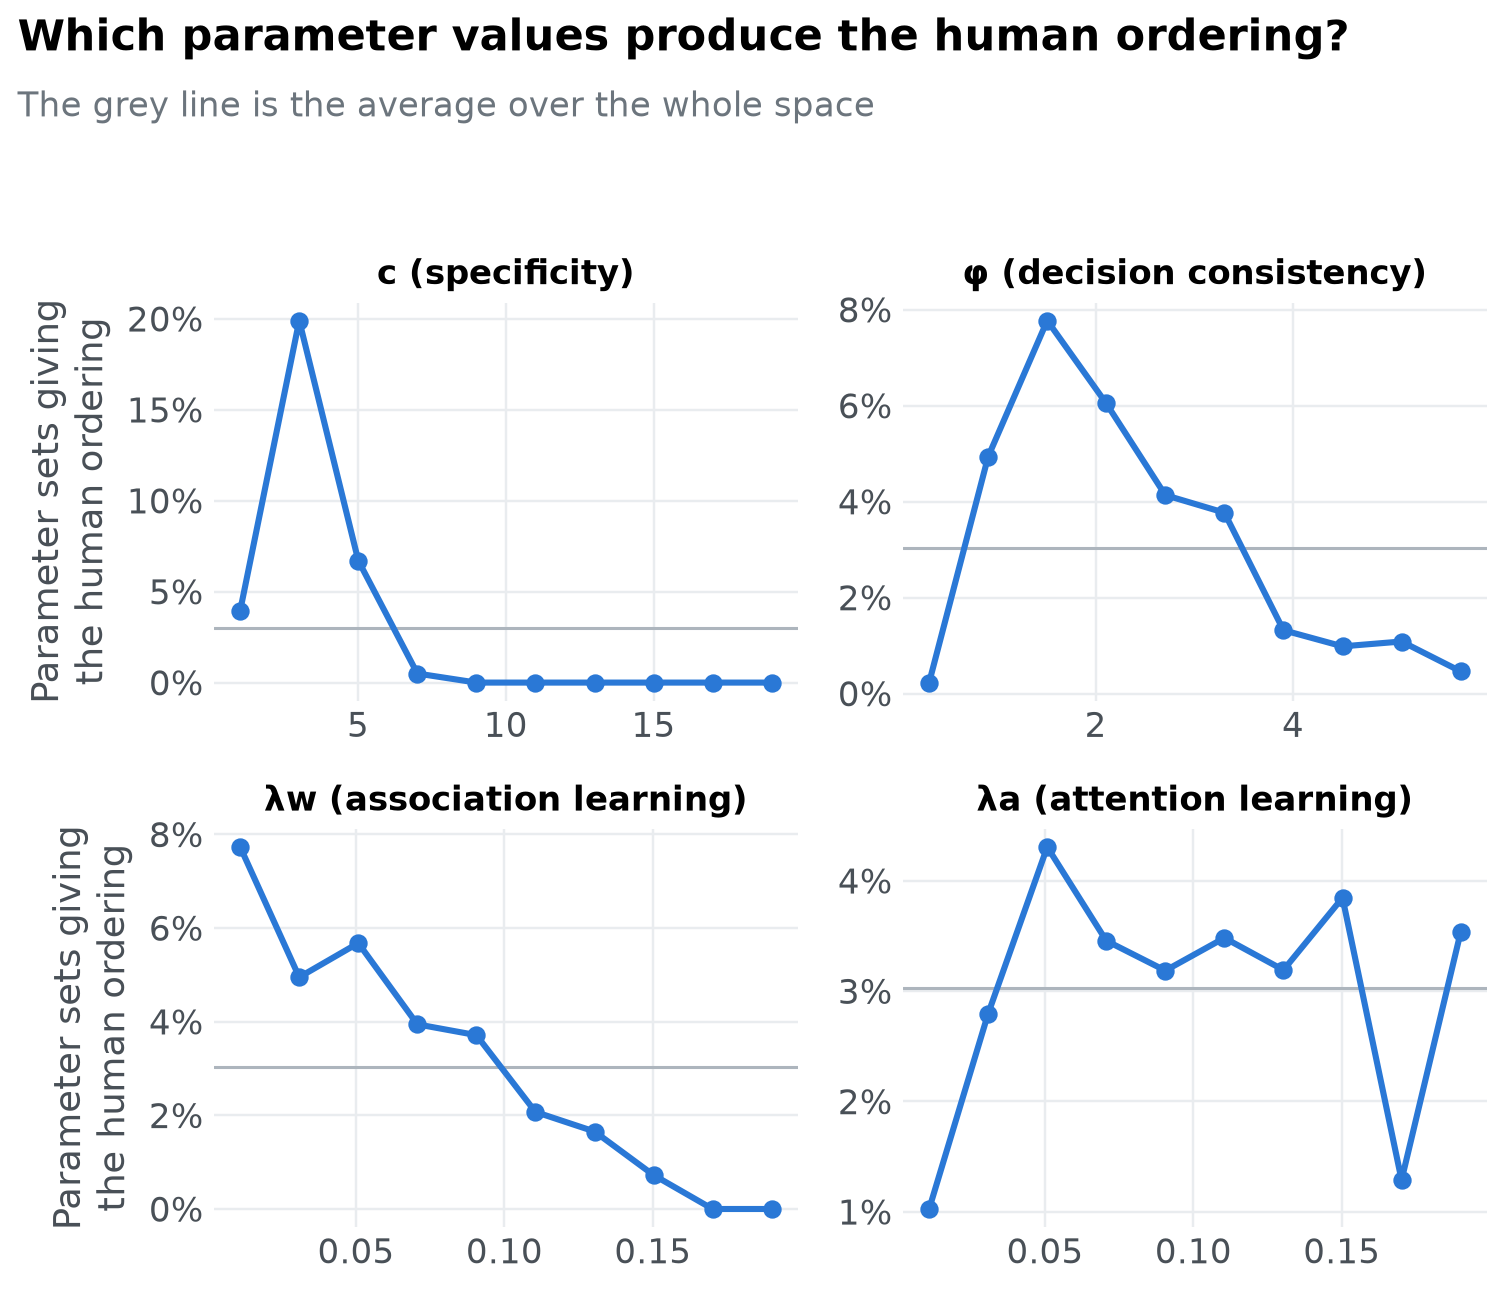

In [23]:
labels = {"c": "c (specificity)", "phi": "φ (decision consistency)",
          "lw": "λw (association learning)", "la": "λa (attention learning)"}
is_human = uniform.order == human
fig, axes = plt.subplots(2, 2, figsize=(7, 6))
for ax, (p, label) in zip(axes.ravel(), labels.items()):
    edges = np.linspace(uniform[p].min(), uniform[p].max(), 11)
    bins = pd.cut(uniform[p], edges, include_lowest=True)
    by_bin = is_human.groupby(bins, observed=True).mean()
    centres = (edges[:-1] + edges[1:]) / 2
    ax.axhline(is_human.mean(), color=grey, linewidth=1)
    ax.plot(centres, by_bin.values, "-o", color=blue, linewidth=2, markersize=5)
    ax.set_title(label, loc="center", fontsize=11)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
for ax in axes[:, 0]:
    ax.set_ylabel("Parameter sets giving\nthe human ordering")
fig.suptitle("Which parameter values produce the human ordering?", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.905, "The grey line is the average over the whole space", color="#6c757d", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.89))
show(fig, "human-ordering-by-parameter")

In [24]:
human_low_c = is_human[uniform.c <= 6].mean()
human_high_c = is_human[uniform.c > 8].mean()
display(Markdown(f"""
A line far above the grey average marks values where the human ordering is common, and a flat line a parameter that hardly matters for it. Specificity $c$ decides most: the human ordering comes from {pct(human_low_c, 1)} of parameter sets with $c \\le 6$ but {pct(human_high_c, 1)} of those with $c > 8$. At high specificity ALCOVE memorises objects one by one, as above, and loses the differences between the types. The human ordering is also more common when association learning is slow. The attention learning rate hardly matters within the range Pitt et al. used, up to 0.2. catlearn's own best fit to these data has an attention learning rate near 1, well outside that range: conclusions about a parameter only hold for the range you searched.
"""))


A line far above the grey average marks values where the human ordering is common, and a flat line a parameter that hardly matters for it. Specificity $c$ decides most: the human ordering comes from 10.5% of parameter sets with $c \le 6$ but 0.0% of those with $c > 8$. At high specificity ALCOVE memorises objects one by one, as above, and loses the differences between the types. The human ordering is also more common when association learning is slow. The attention learning rate hardly matters within the range Pitt et al. used, up to 0.2. catlearn's own best fit to these data has an attention learning rate near 1, well outside that range: conclusions about a parameter only hold for the range you searched.


In [25]:
# the six most common orderings and their colours, used by the figures below
common = list(share.index[:6])
map_colours = dict(zip(common + ["other"], ["#adb5bd", "#eb6834", "#1baf7a", "#e87ba4", "#2a78d6", "#eda100", "#dee2e6"]))
map_colours[human] = blue
short = {"c": "c", "phi": "φ", "lw": "λw", "la": "λa"}

### Ordinal patterns as overlapping relations

An ordering of six types is several qualitative claims at once. The human ordering, I < II < (III, IV, V) < VI, says four things:

1. Type I is easier than Type II.
2. Type II is easier than Types III, IV and V.
3. Types III, IV and V are tied.
4. Type VI is the hardest.

Each claim holds in part of the parameter space, and the human ordering is where all four overlap. Using the same groups as `weak_order()`, we can check each claim for every parameter set in the even sample:

In [26]:
group = (weak_order(torch.tensor(uniform[error_cols].to_numpy())) > 0).sum(dim=2)   # 0 for the easiest group, 1 for the next, ...
relations = pd.DataFrame({
    "I easier than II": group[:, 0] < group[:, 1],
    "II easier than III-V": group[:, 1] < group[:, 2:5].min(dim=1).values,
    "III, IV and V tied": (group[:, 2:5] == group[:, 2:3]).all(dim=1),
    "VI hardest": group[:, 5] > group[:, :5].max(dim=1).values,
})
relations.mean()

I easier than II        0.31025
II easier than III-V    0.36775
III, IV and V tied      0.92075
VI hardest              0.14425
dtype: float64

An UpSet chart shows how the claims overlap. Each column is one combination of claims, marked by the filled dots below it, and the bar above it is the share of the parameter space where exactly that combination holds:

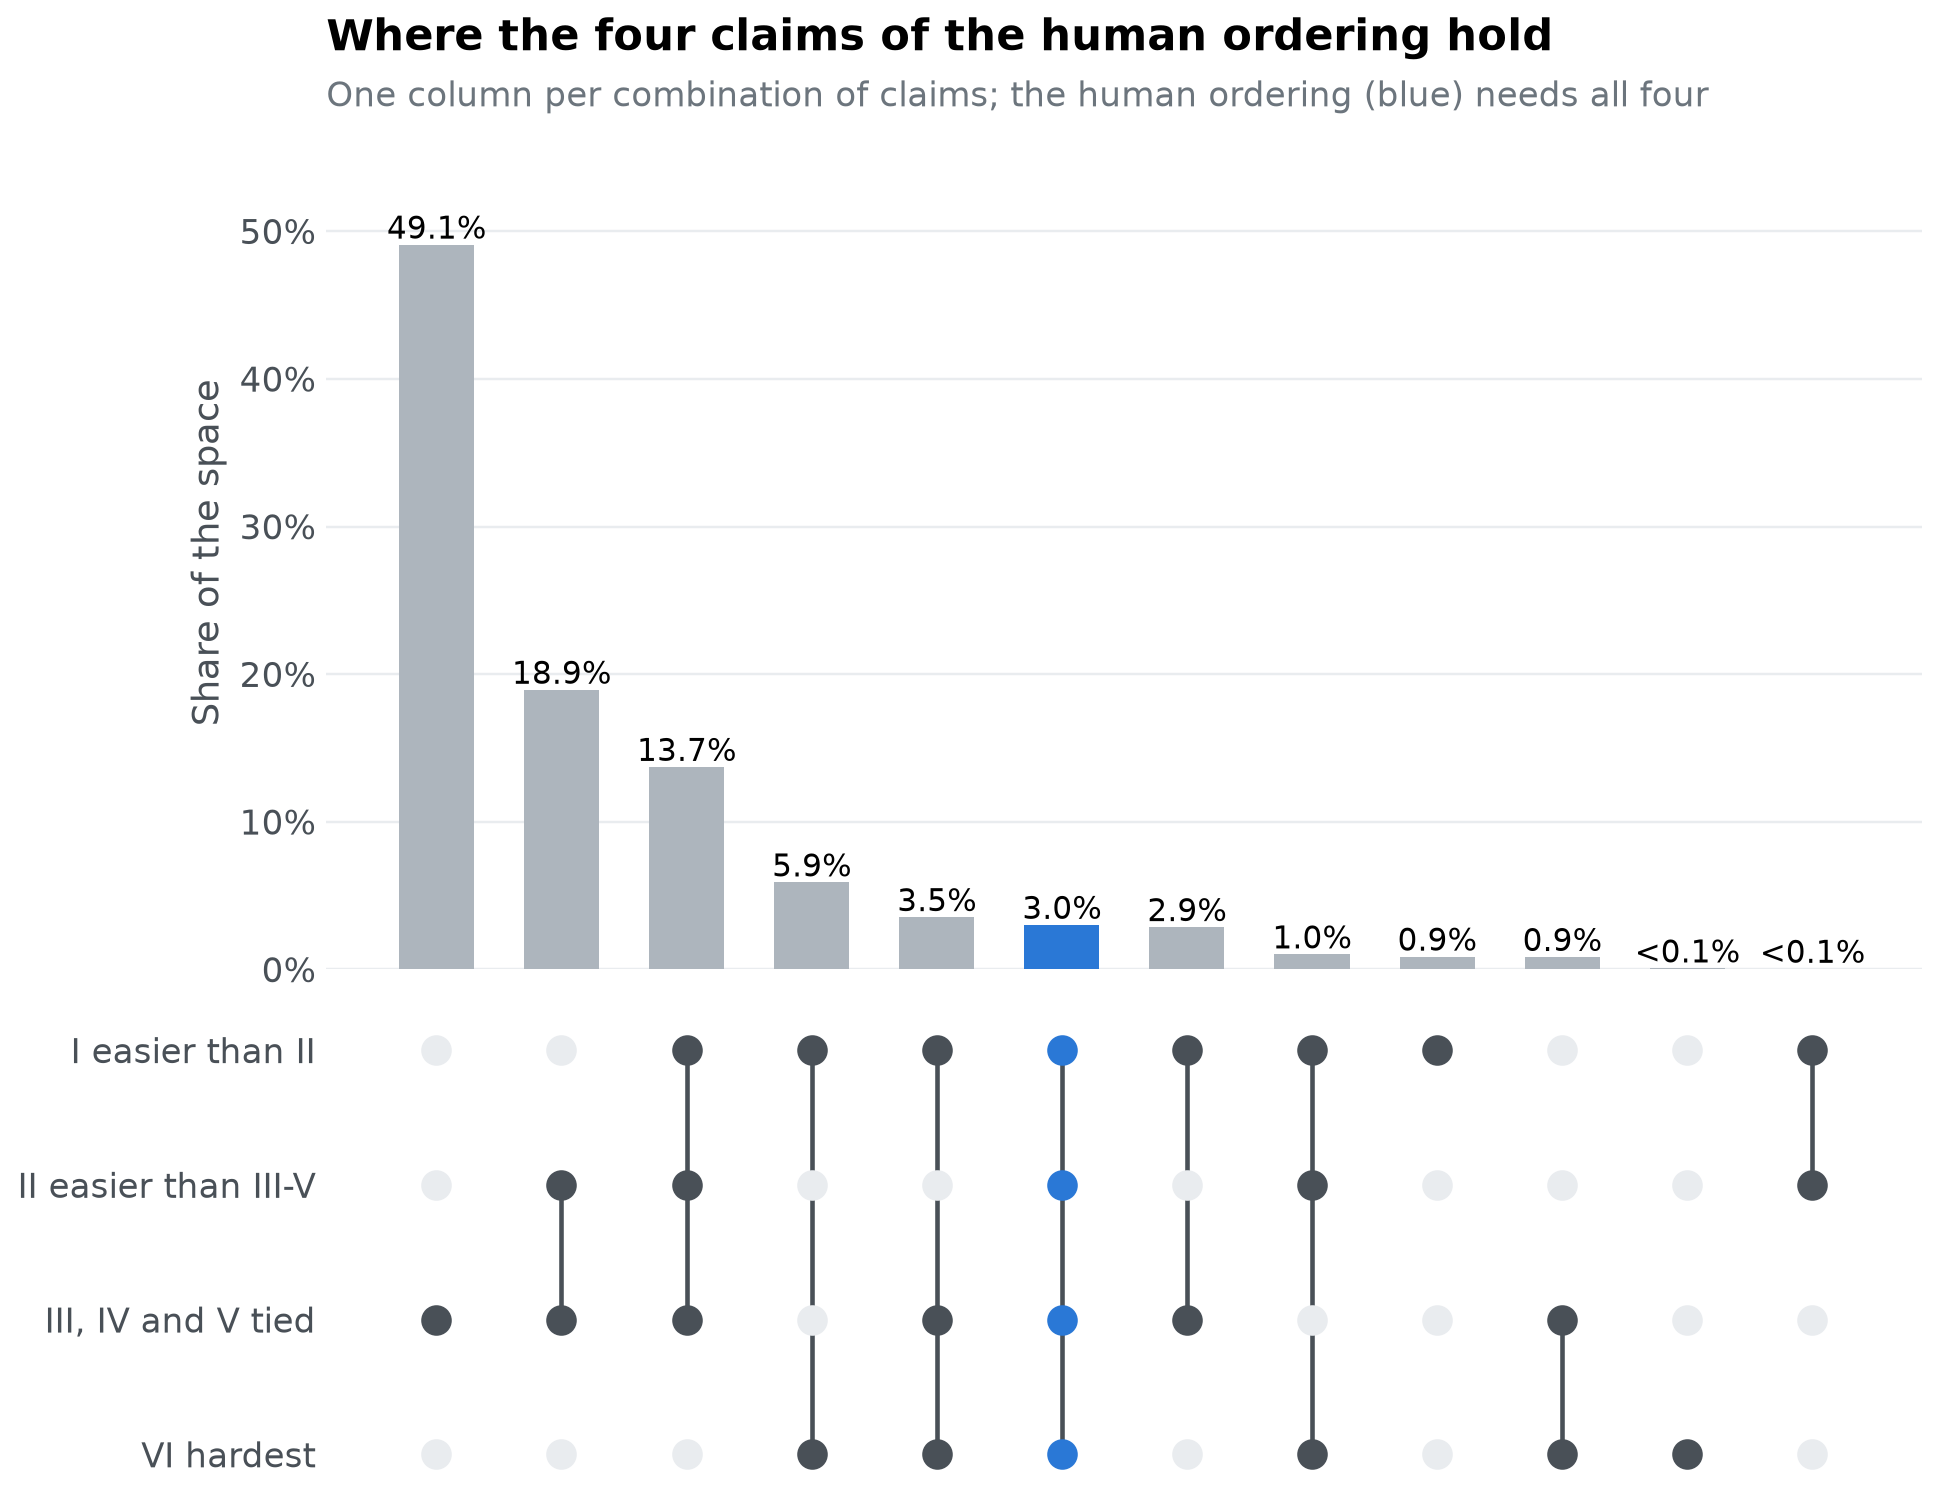

In [27]:
combo = relations.astype(int).astype(str).agg("".join, axis=1)
sizes = combo.value_counts(normalize=True).iloc[:12]
all_four = "1" * relations.shape[1]
fig, (top_ax, bottom_ax) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
xs = np.arange(len(sizes))
top_ax.bar(xs, sizes.values, width=0.6, color=[blue if k == all_four else grey for k in sizes.index])
for x, v in zip(xs, sizes.values):
    top_ax.text(x, v + 0.004, "<0.1%" if v < 0.001 else pct(v, 1), ha="center", fontsize=10)
top_ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
top_ax.set_ylim(0, sizes.max() * 1.15)
top_ax.set_ylabel("Share of the space")
top_ax.grid(axis="x", visible=False)
titled(top_ax, "Where the four claims of the human ordering hold",
       "One column per combination of claims; the human ordering (blue) needs all four")
names = list(relations.columns)
for x, k in zip(xs, sizes.index):
    holds = [c == "1" for c in k]
    ys = [len(names) - 1 - i for i in range(len(names))]
    on = [y for y, h in zip(ys, holds) if h]
    if len(on) > 1:
        bottom_ax.plot([x, x], [min(on), max(on)], color="#495057", linewidth=1.5, zorder=1)
    for y, h in zip(ys, holds):
        bottom_ax.plot(x, y, "o", markersize=9, color=(blue if k == all_four else "#495057") if h else "#e9ecef", zorder=2)
bottom_ax.set_yticks(range(len(names)), names[::-1])
bottom_ax.set_xticks([])
bottom_ax.grid(False)
fig.tight_layout()
show(fig, "claims")

In [28]:
any_three = (relations.sum(axis=1) == 3).mean()
display(Markdown(f"""
On its own, each claim holds in between {pct(relations.mean().min())} and {pct(relations.mean().max())} of the space. The rarest is Type VI being the hardest, in {pct(relations["VI hardest"].mean())}. The four together hold in only {pct((relations.sum(axis=1) == 4).mean(), 1)} of it, the human ordering's share. Another {pct(any_three, 1)} of the space gets three of the four claims right. That is how a model can look close to the data in most of its parameter space and still produce the exact pattern only rarely, and why the definition of a pattern decides the answer.
"""))


On its own, each claim holds in between 14% and 92% of the space. The rarest is Type VI being the hardest, in 14%. The four together hold in only 3.0% of it, the human ordering's share. Another 18.3% of the space gets three of the four claims right. That is how a model can look close to the data in most of its parameter space and still produce the exact pattern only rarely, and why the definition of a pattern decides the answer.


## What else the partition tells you

Pitt et al. (2006) went beyond counting patterns and measuring their regions. This section shows two further analyses of the same saved results, and a way to project a four-parameter partition onto a flat page.

### Did the search level off?

The saved run lists every evaluation in order, so we can count how many distinct patterns the search had found after each number of evaluations. A curve that flattens early suggests the search found most of what it could; one still climbing at the end suggests more patterns remain.

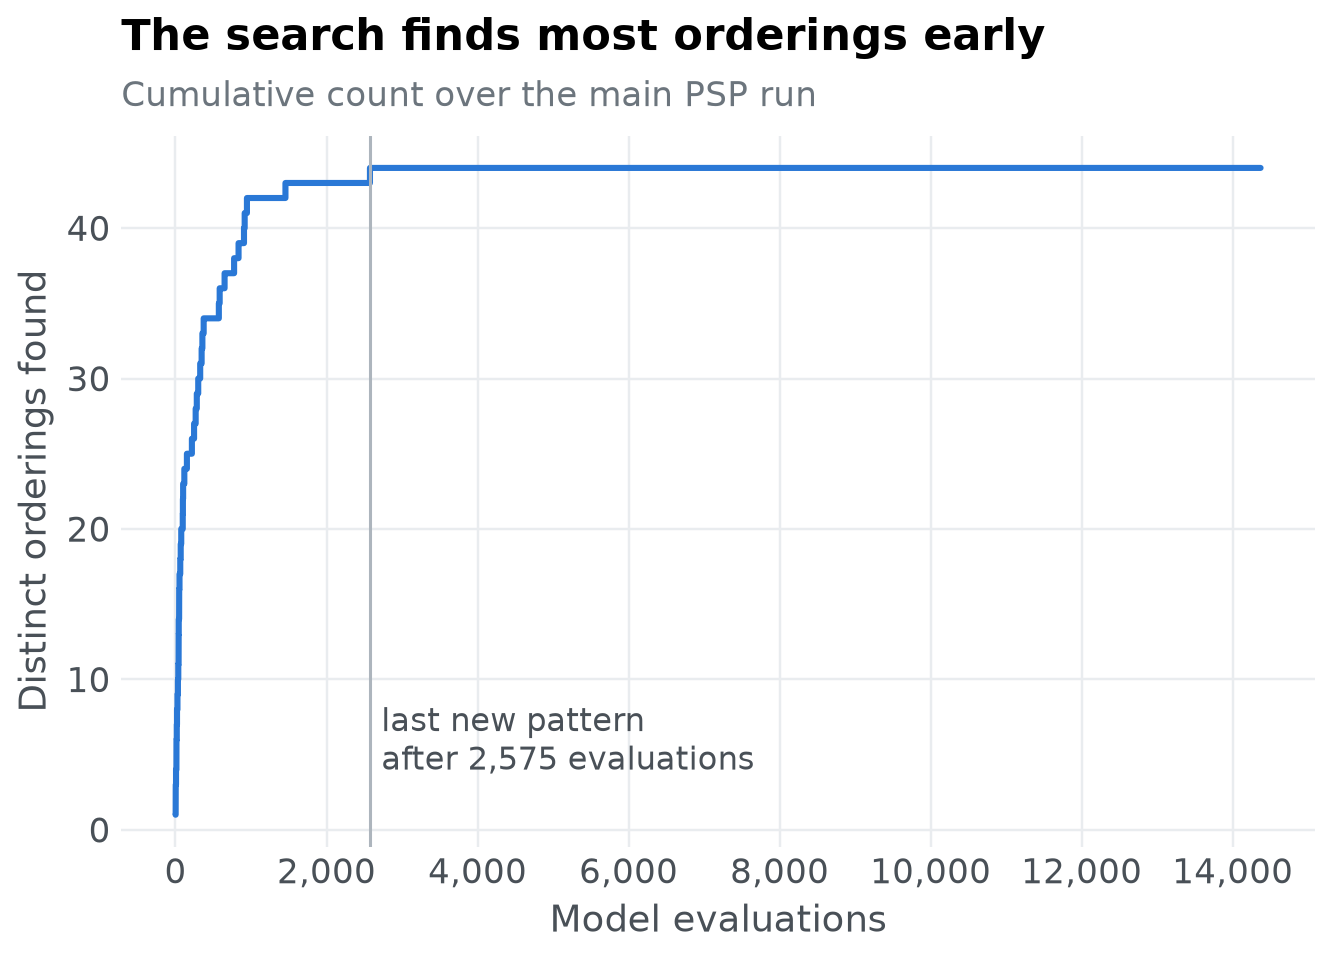

In [29]:
new = ~run.order.duplicated()
discovery = pd.DataFrame({"evaluations": np.arange(1, len(run) + 1), "patterns": new.cumsum()})
last_new = int(np.flatnonzero(new).max()) + 1
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.step(discovery.evaluations, discovery.patterns, where="post", color=blue, linewidth=2)
ax.axvline(last_new, color=grey, linewidth=1)
ax.text(last_new + 150, 4, f"last new pattern\nafter {last_new:,} evaluations", fontsize=10.5, color="#495057")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_xlabel("Model evaluations")
ax.set_ylabel("Distinct orderings found")
titled(ax, "The search finds most orderings early", "Cumulative count over the main PSP run")
show(fig, "discovery")

In [30]:
display(Markdown(f"The last new ordering appeared after {last_new:,} of the {len(run):,} evaluations. The rest of the run filled the regions it had already found."))

The last new ordering appeared after 2,575 of the 14,369 evaluations. The rest of the run filled the regions it had already found.

### Which types does ALCOVE find harder?

Pitt et al. summarised all of ALCOVE's orderings by the average rank of each type: 1 for the easiest group, with tied types sharing the average of their ranks. If the ranks rise from Type I to Type VI, the model's orderings preserve the main trend in the data even when they differ in detail. We compute it two ways: counting every ordering the search found once, and weighting each ordering by its share of the parameter space.

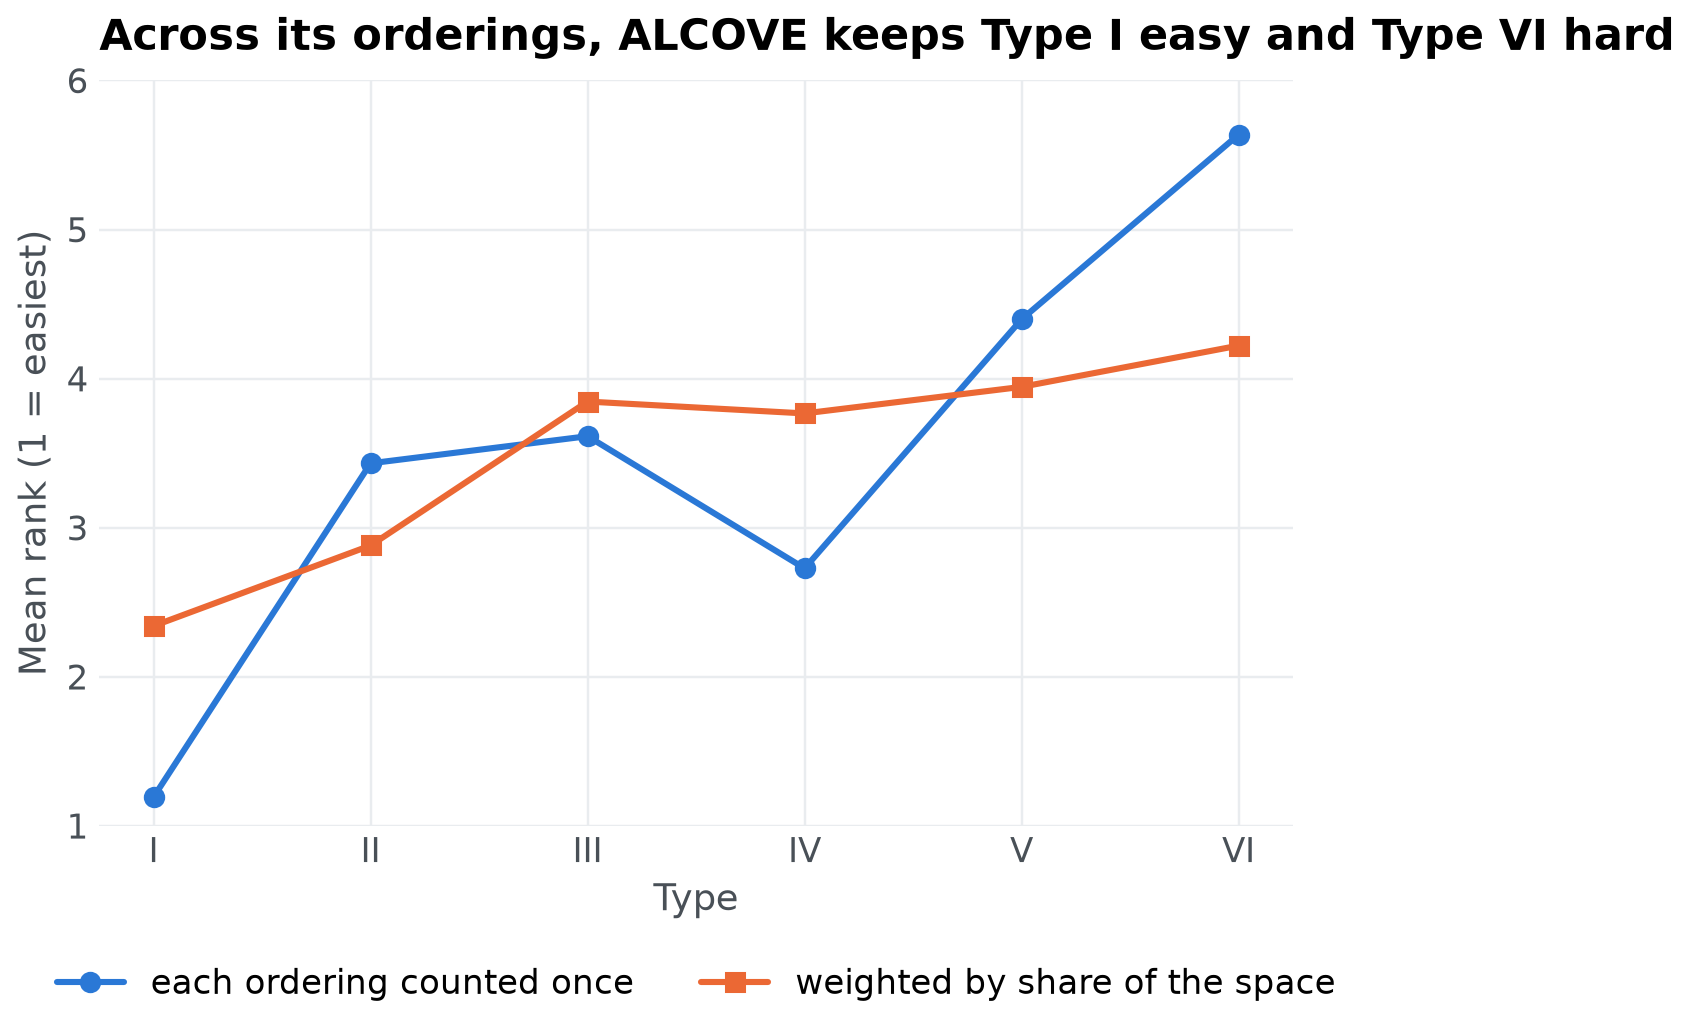

In [31]:
representative = run[~run.order.duplicated()]
by_pattern = type_ranks(torch.tensor(representative[error_cols].to_numpy())).mean(dim=0)
by_volume = type_ranks(torch.tensor(uniform[error_cols].to_numpy())).mean(dim=0)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(TYPES, by_pattern, "-o", color=blue, linewidth=2, markersize=6, label="each ordering counted once")
ax.plot(TYPES, by_volume, "-s", color="#eb6834", linewidth=2, markersize=6, label="weighted by share of the space")
ax.set_ylim(1, 6); ax.set_yticks(range(1, 7))
ax.set_xlabel("Type"); ax.set_ylabel("Mean rank (1 = easiest)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
titled(ax, "Across its orderings, ALCOVE keeps Type I easy and Type VI hard")
show(fig, "mean-rank")

Overall, both lines rise from Type I to Type VI: across its orderings, ALCOVE keeps Type I easy and Type VI hard, as people do. The exception is Type IV. Counting each ordering once, Type IV ranks easier than Types II and III, because many of ALCOVE's rarer orderings put it near the easy end. Weighted by region size, the line is flatter, because the most common outcome, all six types tied, gives every type the same rank.

### The parameter sets in two dimensions

A partition of four parameters can be flattened onto the two directions that best separate its patterns. Linear discriminant analysis (LDA) finds them: put every parameter on the same 0 to 1 scale, and look for the combinations of parameters along which the orderings differ most, relative to how much they vary within themselves. Each evaluated parameter set is then plotted along those two combinations, and the arrows show how much each parameter contributes to them.

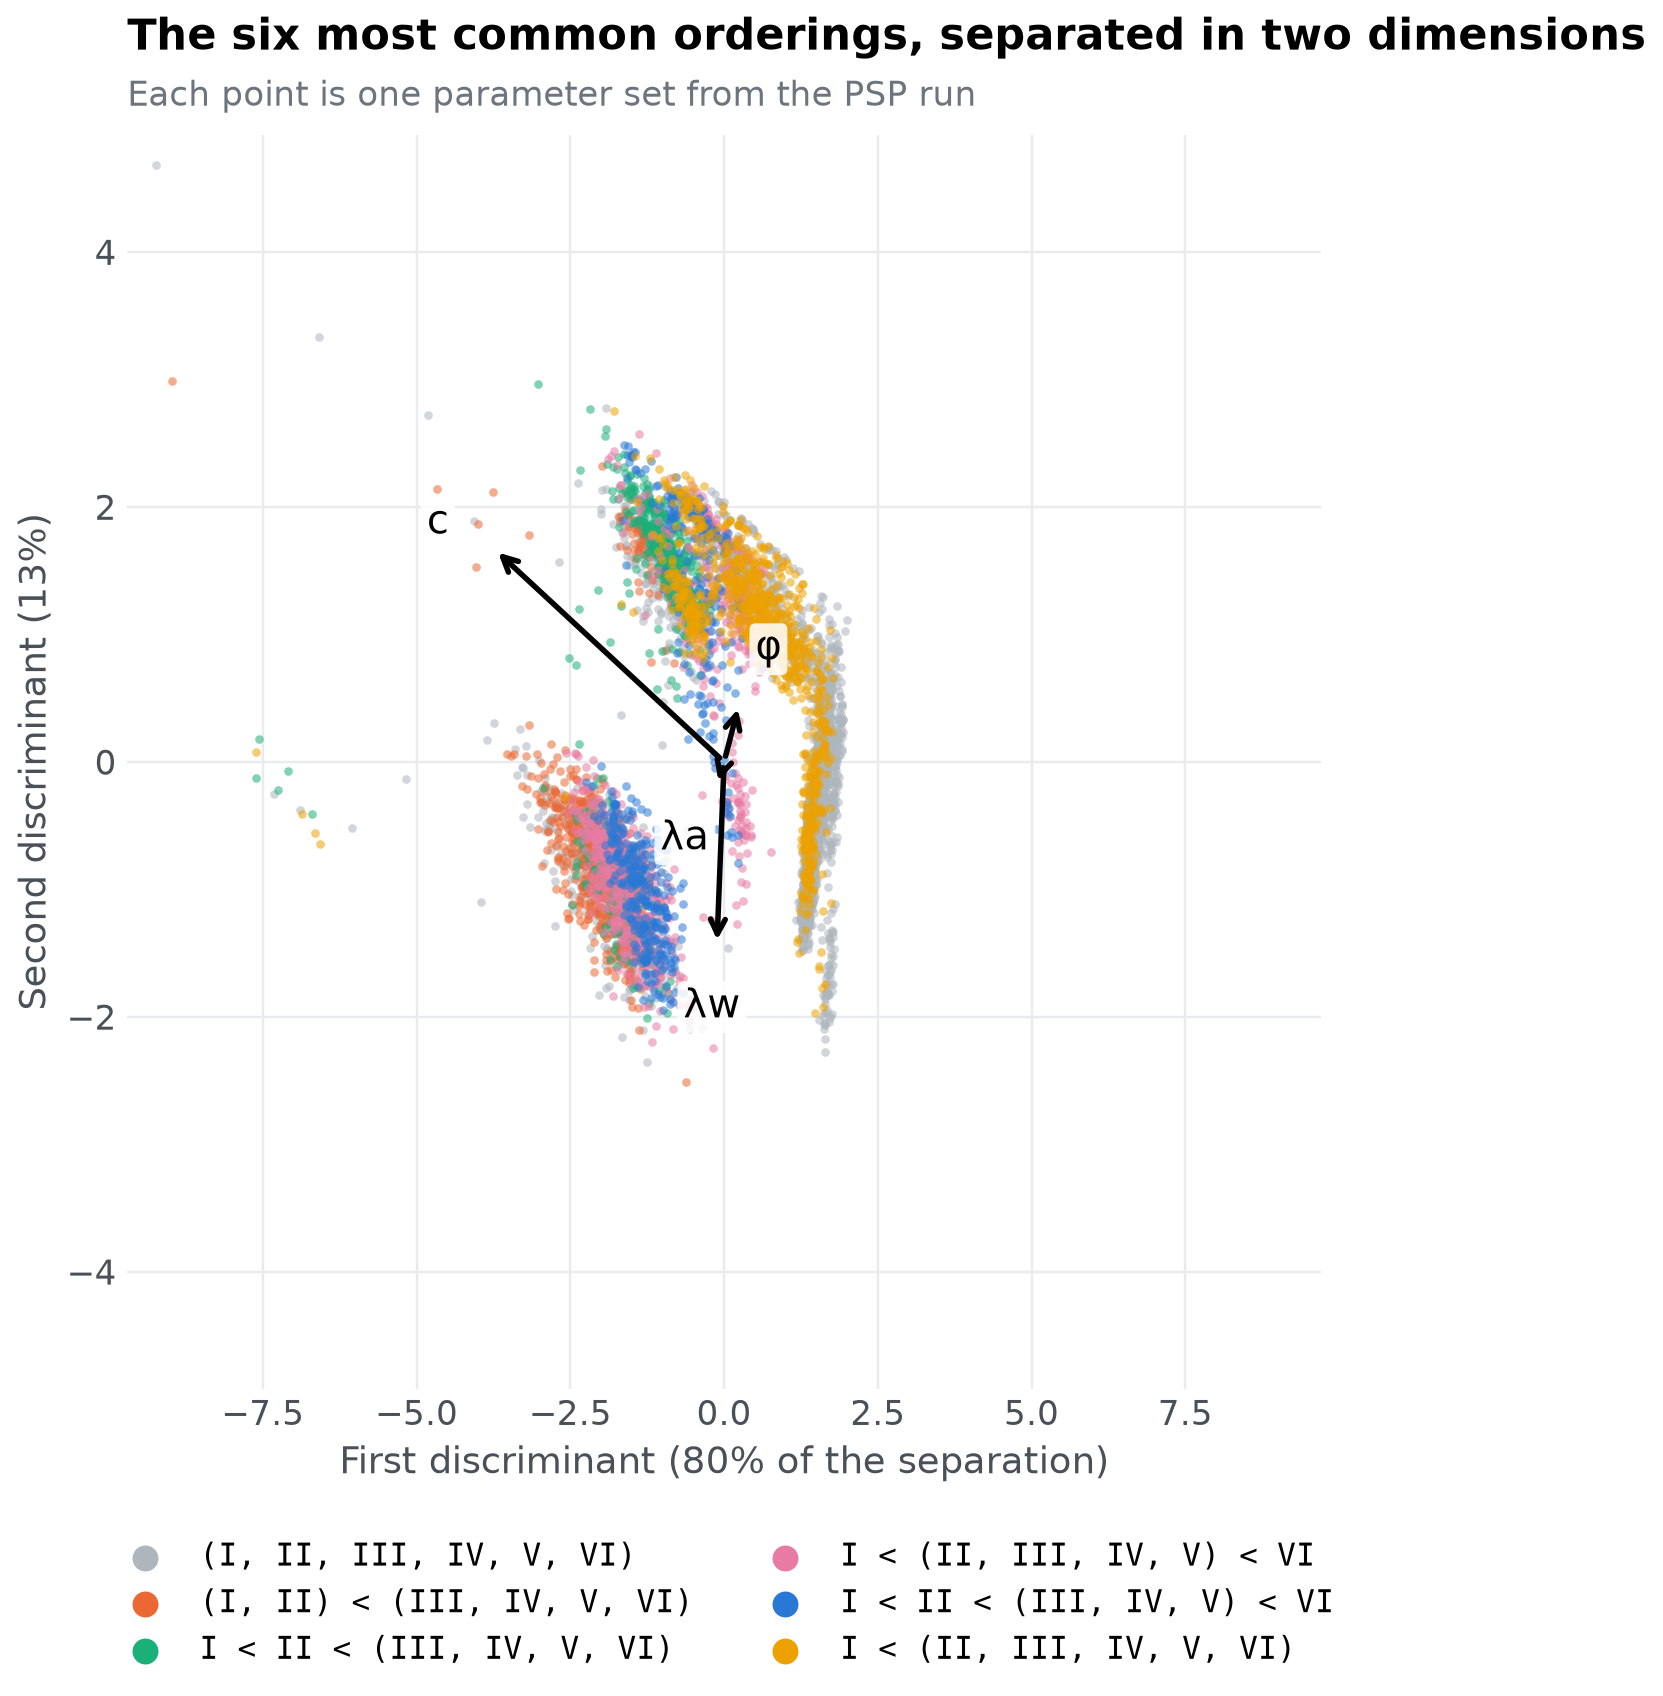

In [32]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

names = list(ALCOVE_PARAMETERS.name)
lower, upper = np.array(ALCOVE_PARAMETERS.lower), np.array(ALCOVE_PARAMETERS.upper)
scaled = (run[names].to_numpy() - lower) / (upper - lower)
keep = run.order.isin(common).to_numpy()
discriminant = LinearDiscriminantAnalysis().fit(scaled[keep], run.order[keep])
projected = discriminant.transform(scaled[keep])[:, :2]
separation = discriminant.explained_variance_ratio_
loadings = discriminant.scalings_[:, :2]
loadings = loadings / np.abs(loadings).max() * 0.8 * np.abs(projected).max(axis=0).min()
fig, ax = plt.subplots(figsize=(7, 7.4))
for o in common:
    part = projected[(run.order[keep] == o).to_numpy()]
    ax.scatter(part[:, 0], part[:, 1], s=8, color=map_colours[o], alpha=0.55, linewidths=0, label=o)
for (dx, dy), p in zip(loadings, names):
    ax.annotate("", xy=(dx, dy), xytext=(0, 0), arrowprops={"arrowstyle": "->", "linewidth": 1.8, "color": "black"})
    length = float(np.hypot(dx, dy)) or 1.0
    ax.annotate(short[p], (dx, dy), xytext=(20 * dx / length, 20 * dy / length), textcoords="offset points",
                fontsize=13, ha="center", va="center",
                bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.85})
reach = np.maximum(np.abs(projected).max(axis=0), np.abs(loadings).max(axis=0) * 1.25)
ax.set_xlim(-reach[0] * 1.05, reach[0] * 1.05); ax.set_ylim(-reach[1] * 1.05, reach[1] * 1.05)
ax.set_xlabel(f"First discriminant ({pct(separation[0])} of the separation)")
ax.set_ylabel(f"Second discriminant ({pct(separation[1])})")
legend = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, markerscale=3, prop={"family": "monospace", "size": 10})
for handle in legend.legend_handles:
    handle.set_alpha(1)
titled(ax, "The six most common orderings, separated in two dimensions", "Each point is one parameter set from the PSP run")
show(fig, "discriminants")

Orderings that form separate clouds occupy different parts of the parameter space, and the arrows show which parameters separate them: the longer the arrow, the more that parameter matters for telling the orderings apart. The projection is linear, so orderings whose regions curve around each other can still overlap in it.

## Step 5: check that the conclusions hold

Every PSP analysis rests on choices that could have been made differently. Pitt et al. recommend trying a few and checking whether the conclusions change. `run_alcove.py` repeats parts of the analysis in three ways.

### Other trial orders

ALCOVE's predictions depend a little on the order of the training trials, which is why Pitt et al. ran PSP on 20 different orders. We repeated the full PSP run with four more:

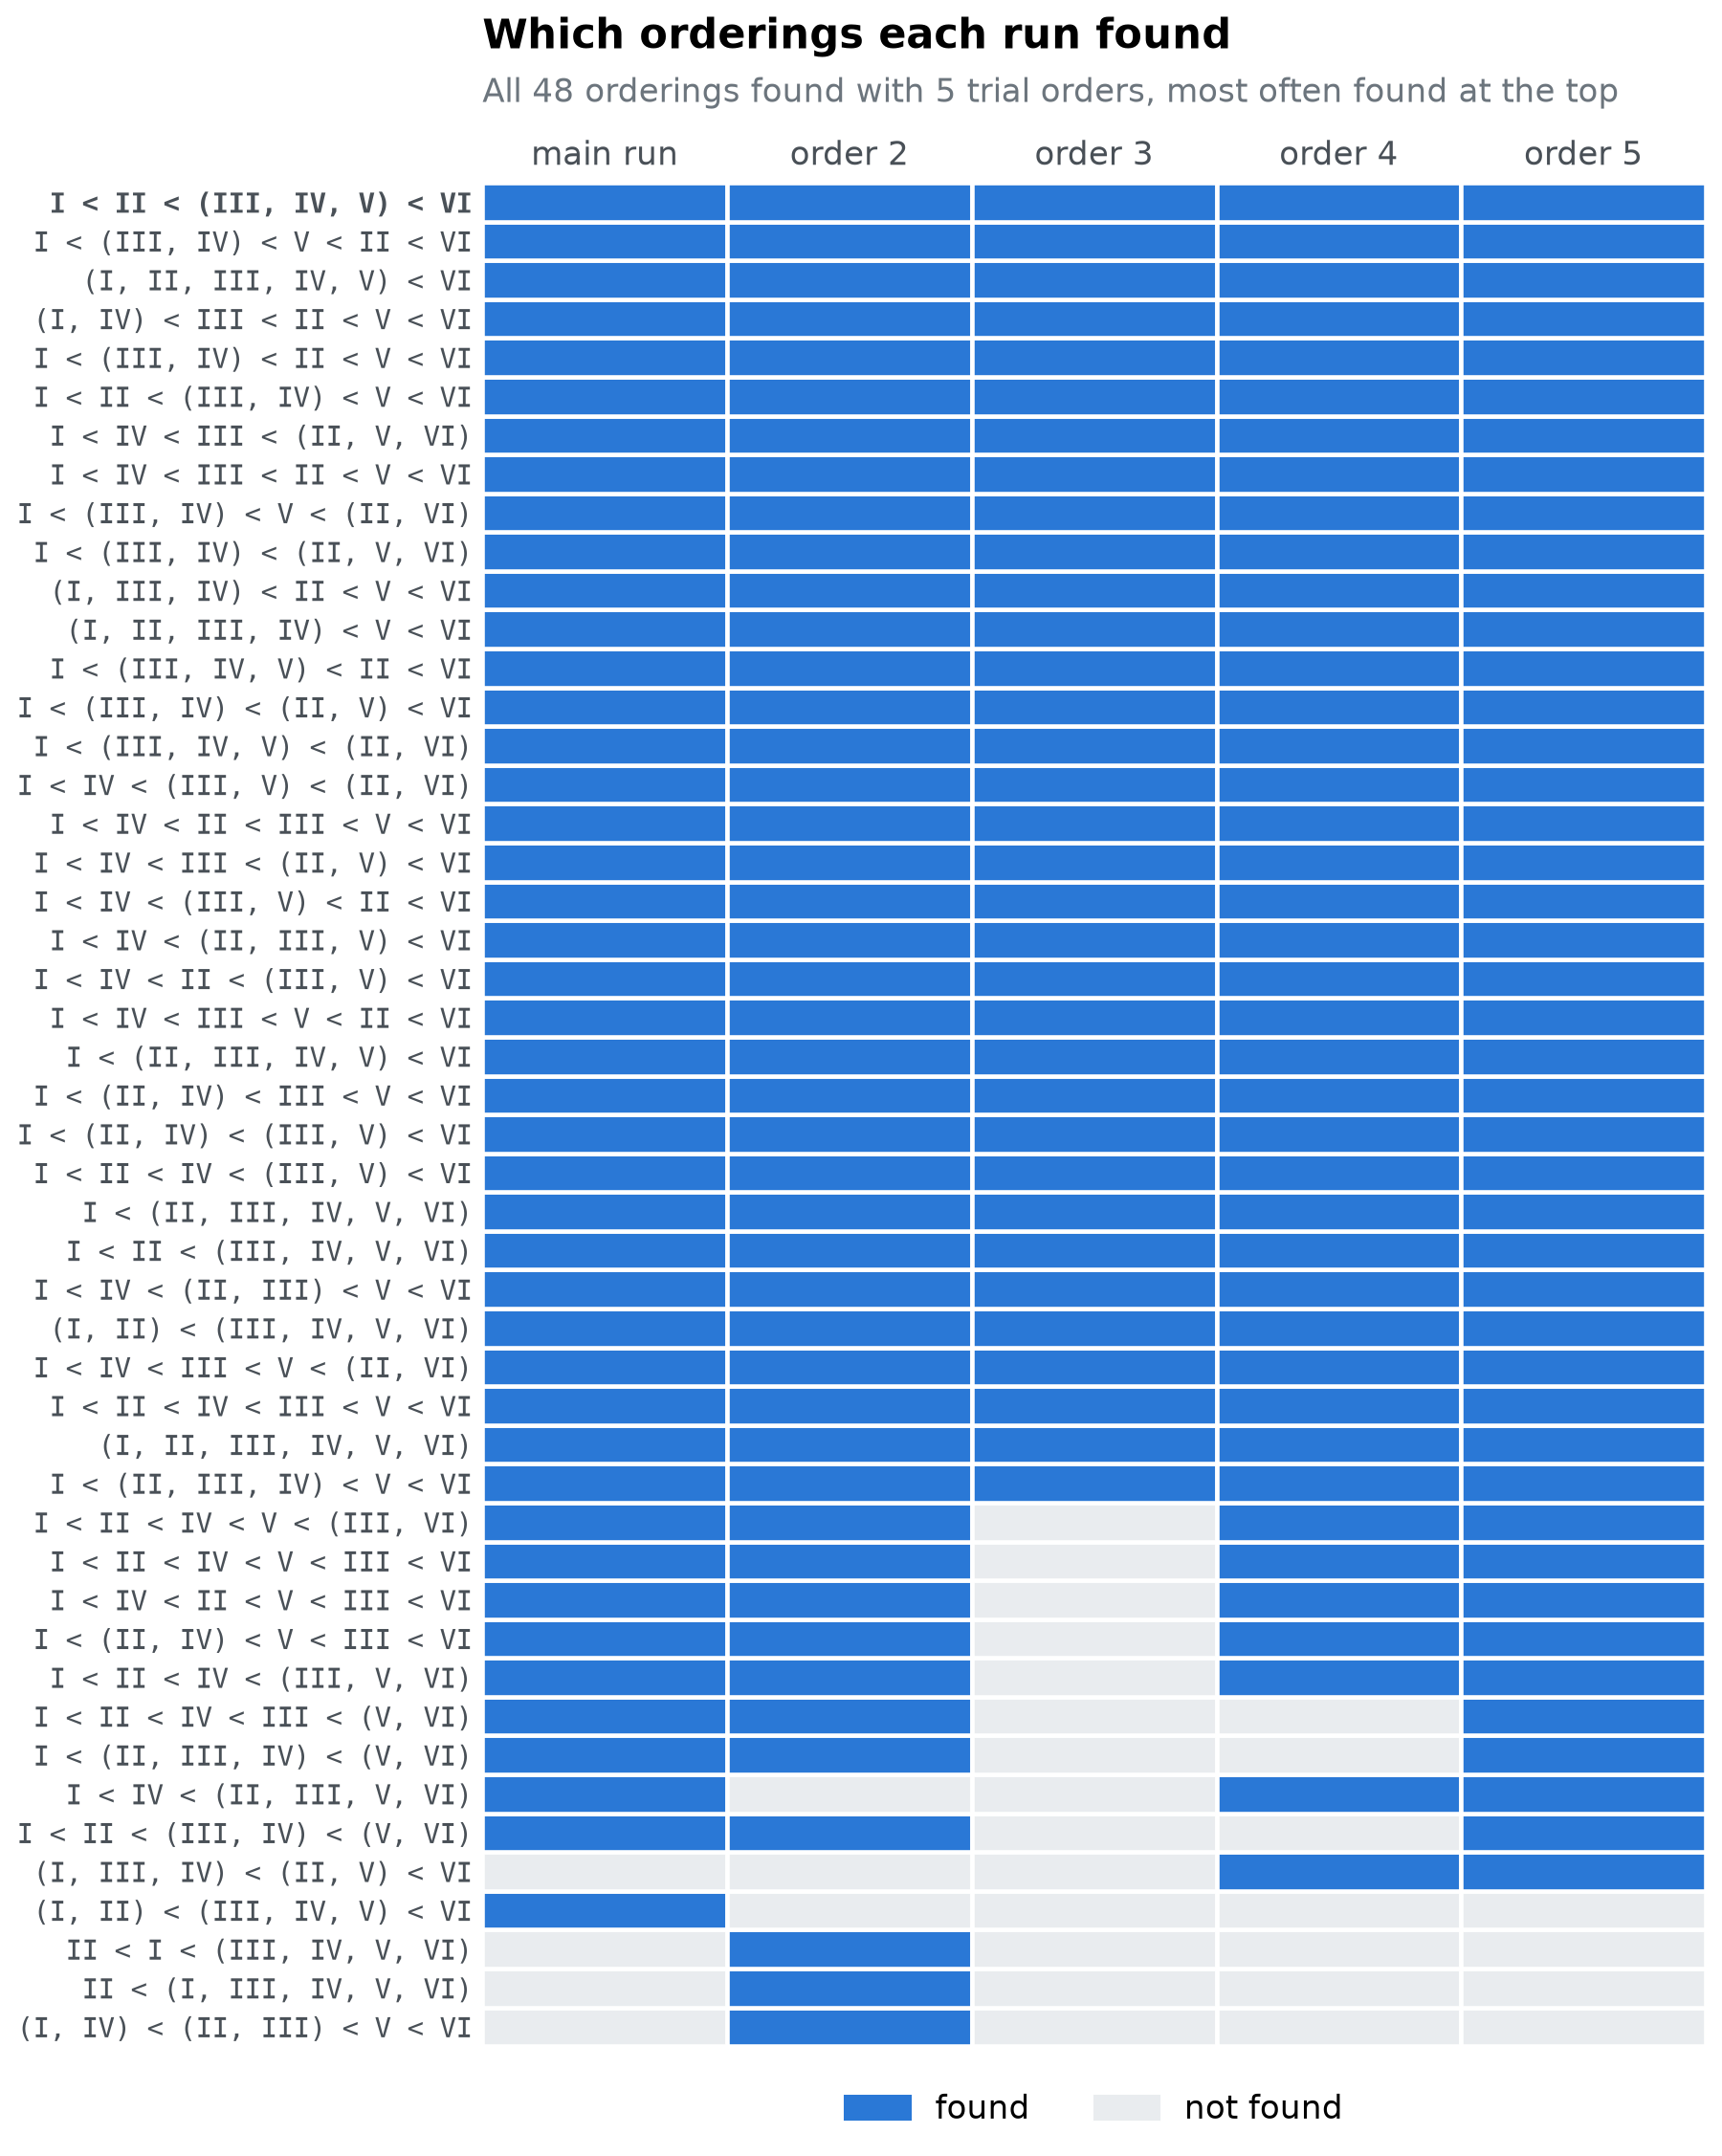

In [33]:
orders = read_result("trial-orders.csv")
orders = pd.concat([pd.DataFrame({"trial_order": 7624, "order": found}), orders[["trial_order", "order"]]], ignore_index=True)
runs = orders.trial_order.unique()
times_found = orders.order.value_counts()
universal = list(times_found.index[times_found == len(runs)])
level = (times_found + (times_found.index == human) * 0.5).sort_values().index
columns = ["main run"] + [f"order {i}" for i in range(2, len(runs) + 1)]
fig, ax = plt.subplots(figsize=(7.5, 11.5))
for i, o in enumerate(level):
    for j, trial_order in enumerate(runs):
        found_here = ((orders.order == o) & (orders.trial_order == trial_order)).any()
        ax.add_patch(mpatches.Rectangle((j, i), 1, 1, facecolor=blue if found_here else "#e9ecef", edgecolor="white", linewidth=1.5))
ax.set_xlim(0, len(runs)); ax.set_ylim(0, len(level))
ax.set_xticks(np.arange(len(runs)) + 0.5, columns); ax.xaxis.tick_top()
ax.set_yticks(np.arange(len(level)) + 0.5, level, family="monospace", fontsize=9.5)
for tick in ax.get_yticklabels():
    if tick.get_text() == human:
        tick.set_fontweight("bold")
ax.grid(False)
handles = [mpatches.Patch(color=blue, label="found"), mpatches.Patch(color="#e9ecef", label="not found")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2)
titled(ax, "Which orderings each run found", f"All {len(level)} orderings found with {len(runs)} trial orders, most often found at the top", pad=18)
show(fig, "orderings-by-trial-order")

In [34]:
per_run = orders.trial_order.value_counts()
display(Markdown(f"""
The runs found between {per_run.min()} and {per_run.max()} orderings each, and {len(times_found)} different orderings across all {len(runs)}. {len(universal)} of them were found in every run, and the human ordering is {"one of them" if human in universal else "not one of them"}. Pitt et al. report the same kind of picture: a stable core of orderings that ALCOVE produces whatever the trial order (17 in their analysis), and a fringe of rarer orderings that depend on it.
"""))


The runs found between 34 and 45 orderings each, and 48 different orderings across all 5. 34 of them were found in every run, and the human ordering is one of them. Pitt et al. report the same kind of picture: a stable core of orderings that ALCOVE produces whatever the trial order (17 in their analysis), and a fringe of rarer orderings that depend on it.


### Another threshold for ties

The gap of 0.025 decides which types count as tied. Applying `weak_order()` with other gaps to the evenly spread sample shows how much that choice matters. Only the mean errors are needed, so nothing has to be run again:

In [35]:
errors = torch.tensor(uniform[error_cols].to_numpy())


def regroup(gap):
    return np.array([describe_order(p) for p in weak_order(errors, gap=gap)])


gaps = [0.015, 0.025, 0.035]
rows = []
for g in gaps:
    orders_g = regroup(g)
    human_g = describe_order(weak_order(human_curves(), gap=g))
    rows.append({"gap": g, "human_ordering": human_g, "orderings_found": len(np.unique(orders_g)),
                 "share_human": pct((orders_g == human_g).mean(), 1)})
sensitivity = pd.DataFrame(rows)
sensitivity

,gap,human_ordering,orderings_found,share_human
0,0.015,"I < II < (III, IV, V) < VI",35,4.9%
1,0.025,"I < II < (III, IV, V) < VI",36,3.0%
2,0.035,"I < II < (III, IV, V) < VI",34,1.6%


In [36]:
display(Markdown(f"""
The human data give the same ordering with every gap, so the target of the analysis does not change. A smaller gap separates more types and produces more orderings; a larger gap merges more and produces fewer. The question to ask is whether the human ordering stays one of ALCOVE's orderings and keeps a share of the space of the same size. Here, the human ordering covers {", ".join(sensitivity.share_human)} of the space with gaps of {", ".join(map(str, gaps))}.
"""))


The human data give the same ordering with every gap, so the target of the analysis does not change. A smaller gap separates more types and produces more orderings; a larger gap merges more and produces fewer. The question to ask is whether the human ordering stays one of ALCOVE's orderings and keeps a share of the space of the same size. Here, the human ordering covers 4.9%, 3.0%, 1.6% of the space with gaps of 0.015, 0.025, 0.035.


### More simulated learners

Each evaluation averaged over only 5 simulated learners per type, to keep the run affordable. Re-evaluating 500 of the evenly spread parameter sets with 20 learners shows whether that changed the answers:

In [37]:
learners = read_result("learners.csv")
pd.Series({
    "same_ordering": (learners.learners_5 == learners.learners_20).mean(),
    "human_with_5": (learners.learners_5 == human).mean(),
    "human_with_20": (learners.learners_20 == human).mean(),
})

same_ordering    0.988
human_with_5     0.038
human_with_20    0.038
dtype: float64

In [38]:
checked = uniform[error_cols].to_numpy()[:500]
margin = np.array([np.abs(np.diff(np.sort(e)) - 0.025).min() for e in checked])
changed = (learners.learners_5 != learners.learners_20).to_numpy()
display(Markdown(f"""
With 20 learners, {pct((~changed).mean(), 1)} of the parameter sets keep the same ordering. The ones that change sit on the edge of a tie: their closest gap between two types is a median of {np.median(margin[changed]):.4f} away from the 0.025 threshold, against {np.median(margin[~changed]):.4f} for the rest, so a little averaging noise tips them across it. The share of the human ordering is {"the same" if abs((learners.learners_5 == human).mean() - (learners.learners_20 == human).mean()) < 0.01 else "similar"} with 5 and with 20 learners, so the conclusions do not depend on the small number of simulated learners.
"""))


With 20 learners, 98.8% of the parameter sets keep the same ordering. The ones that change sit on the edge of a tie: their closest gap between two types is a median of 0.0007 away from the 0.025 threshold, against 0.0113 for the rest, so a little averaging noise tips them across it. The share of the human ordering is the same with 5 and with 20 learners, so the conclusions do not depend on the small number of simulated learners.


## What we learned

In [39]:
display(Markdown(f"""
- ALCOVE produces {len(found)} of the 4,683 possible orderings of the six types, so it is far from able to fit any ordering.
- The ordering people show is one of them, and it covers {pct((uniform.order == human).mean(), 1)} of the parameter space.
- The single most common outcome is that all six types are learned equally well, mostly because ALCOVE memorises every object when its specificity $c$ is high. The human ordering needs low specificity.
- The human ordering is {"found with every trial order" if human in universal else "not found with every trial order"}, and the conclusions hold for other thresholds for ties and for more simulated learners.

The steps carry over to any slow model: wrap it so one radius suits every parameter, batch it so one call evaluates many parameter sets, define patterns that answer your question and can be counted, pilot before you run, save the run, summarise the partition parameter by parameter, and check the conclusions against the choices you made along the way.
"""))


- ALCOVE produces 44 of the 4,683 possible orderings of the six types, so it is far from able to fit any ordering.
- The ordering people show is one of them, and it covers 3.0% of the parameter space.
- The single most common outcome is that all six types are learned equally well, mostly because ALCOVE memorises every object when its specificity $c$ is high. The human ordering needs low specificity.
- The human ordering is found with every trial order, and the conclusions hold for other thresholds for ties and for more simulated learners.

The steps carry over to any slow model: wrap it so one radius suits every parameter, batch it so one call evaluates many parameter sets, define patterns that answer your question and can be counted, pilot before you run, save the run, summarise the partition parameter by parameter, and check the conclusions against the choices you made along the way.


## References

Kontkanen, P., Myllymäki, P., Buntine, W., Rissanen, J., & Tirri, H. (2005). An MDL framework for data clustering. In P. Grünwald, I. J. Myung, & M. A. Pitt (Eds.), *Advances in minimum description length: Theory and applications* (pp. 323–354). MIT Press. <https://doi.org/10.7551/mitpress/1114.003.0018>

Kruschke, J. K. (1992). ALCOVE: An exemplar-based connectionist model of category learning. *Psychological Review, 99*(1), 22–44. <https://doi.org/10.1037/0033-295X.99.1.22>

Nosofsky, R. M., Gluck, M. A., Palmeri, T. J., McKinley, S. C., & Glauthier, P. (1994). Comparing models of rule-based classification learning: A replication and extension of Shepard, Hovland, and Jenkins (1961). *Memory & Cognition, 22*(3), 352–369. <https://doi.org/10.3758/BF03200862>

Pitt, M. A., Kim, W., Navarro, D. J., & Myung, J. I. (2006). Global model analysis by parameter space partitioning. *Psychological Review, 113*(1), 57–83. <https://doi.org/10.1037/0033-295X.113.1.57>

Shepard, R. N., Hovland, C. I., & Jenkins, H. M. (1961). Learning and memorization of classifications. *Psychological Monographs: General and Applied, 75*(13), 1–42. <https://doi.org/10.1037/h0093825>

Wills, A. J., Dome, L., Edmunds, C., Honke, G., Inkster, A., Schlegelmilch, R., & Spicer, S. (2025). *catlearn: Formal psychological models of categorization and learning* (R package version 1.1). <https://doi.org/10.32614/CRAN.package.catlearn>